In [31]:
library(devtools)
library(arrow)
library(io)
library(dplyr)

load_all("../../../peags")

ℹ Loading peags


In [2]:
flip_swapped_groups <- function(
	df,
	group_col = "group",
	sens_col = "sensitivity",
	spec_col = "specificity",
	prev_col = "peags_prevalence",
	method = "youden"
) {

	accepted_methods <- c("youden", "joint", "prevalence")
	if (length(method) != 1L || is.na(method) || !method %in% accepted_methods) {
		stop("`method` must be one of: ", paste(accepted_methods, collapse = ", "))
	}

	if (!all(group_col %in% names(df))) {
		stop("`group_col` must reference existing column(s) in `df`: ",
			paste(setdiff(group_col, names(df)), collapse = ", "))
	}

	# Build grouping key from one or more columns
	if (length(group_col) == 1L) {
		group_key <- df[[group_col]]
	} else {
		group_key <- interaction(df[group_col], drop = TRUE)
	}

	# prevalence is a group-level parameter: assert it's constant within group
	n_prev <- tapply(df[[prev_col]], group_key, function(x) length(unique(signif(x, 10))))
	stopifnot(all(n_prev == 1))

	youden <- df[[sens_col]] + df[[spec_col]] - 1
	med_youden <- ave(youden, group_key, FUN = function(x) median(x, na.rm = TRUE))

	if (method == "youden") {
		flip <- med_youden < 0
	}

	if (method == "joint") {
		flip <- (med_youden < 0 & df[[prev_col]] > 0.4 &
				df[[prev_col]] < 0.6) | df[[prev_col]] >= 0.6
	}

	if (method == "prevalence") {
		flip <- df[[prev_col]] > 0.5
	}

	sens <- df[[sens_col]]
	spec <- df[[spec_col]]

	df[[sens_col]] <- ifelse(flip, 1 - spec, sens)
	df[[spec_col]] <- ifelse(flip, 1 - sens, spec)
	df[[prev_col]] <- ifelse(flip, 1 - df[[prev_col]], df[[prev_col]])

	df$flipped <- flip
	df$youden <- df[[sens_col]] + df[[spec_col]] - 1

	df
}

In [3]:
repo_root <- normalizePath("../..")

dataset <- "seqc2"
data_root <- file.path(repo_root, "data", dataset)
matrix_dir <- file.path(data_root, "matrix")

In [4]:
matrix_paths <- Sys.glob(file.path(matrix_dir, "*.matrix.parquet"))

In [5]:
#' Vectorized binary classification metrics for a logical prediction matrix
compute_binary_metrics <- function(pred_mat, truth) {
	pred_mat <- as.matrix(pred_mat) > 0
	truth    <- as.logical(truth)
	
	tp <- colSums(pred_mat & truth, na.rm = TRUE)
	fp <- colSums(pred_mat & !truth, na.rm = TRUE)
	fn <- colSums(!pred_mat & truth, na.rm = TRUE)
	tn <- colSums(!pred_mat & !truth, na.rm = TRUE)
	
	prevalence  <- mean(truth, na.rm = TRUE)
	sensitivity <- ifelse((tp + fn) > 0, tp / (tp + fn), NA_real_)
	specificity <- ifelse((tn + fp) > 0, tn / (tn + fp), NA_real_)
	precision   <- ifelse((tp + fp) > 0, tp / (tp + fp), NA_real_)
	f1          <- ifelse(
		!is.na(precision) & !is.na(sensitivity) & (precision + sensitivity) > 0,
		2 * (precision * sensitivity) / (precision + sensitivity),
		NA_real_
	)
	
	data.frame(
		tp          = tp,
		fp          = fp,
		fn          = fn,
		tn          = tn,
		prevalence  = prevalence,
		sensitivity = sensitivity,
		specificity = specificity,
		precision   = precision,
		f1          = f1,
		youden      = sensitivity + specificity - 1,
		row.names   = NULL,
		stringsAsFactors = FALSE
	)
}

#' Calculate conventional per-platform benchmarking metrics against a truth set
calculate_conventional_performance <- function(df, 
												sv_cols, 
												group_name, 
												svtype, 
												truth_col = "seqc2_validated_svs") {
	X       <- as.matrix(df[, sv_cols, drop = FALSE])
	metrics <- compute_binary_metrics(X, df[[truth_col]])
	
	cbind(
		data.frame(
		group          = group_name,
		svtype         = svtype,
		n_calls        = nrow(X),
		method         = "Conventional",
		platform       = sv_cols,
		call_frequency = colMeans(X > 0, na.rm = TRUE),
		row.names      = NULL,
		stringsAsFactors = FALSE
		),
		metrics
	)
	}

#' Calculate consensus call performance across thresholds and caller combinations
calc_consensus_call_perf <- function(df, 
										sv_cols, 
										truth_col = "seqc2_validated_svs",
										group_name = NA_character_,
										svtype = "ALL",
										consensus_start = 2,
										combinations = FALSE) {
	
	sv_mat      <- as.matrix(df[, sv_cols, drop = FALSE]) > 0
	n_consensus <- rowSums(sv_mat)
	thresholds  <- seq(from = consensus_start, to = length(sv_cols), by = 1)
	
	# Build a list of prediction vectors and track the threshold k for each rule
	pred_cols <- list()
	k_vals    <- integer(0)
	
	for (k in thresholds) {
		pred_cols[[paste0("any_", k)]] <- n_consensus >= k
		k_vals <- c(k_vals, k)
		
		if (combinations) {
		combos <- combn(sv_cols, k, simplify = FALSE)
		for (cols in combos) {
			combo_label <- paste(cols, collapse = "+")
			pred_cols[[combo_label]] <- rowSums(sv_mat[, cols, drop = FALSE]) == k
		}
		k_vals <- c(k_vals, rep(k, length(combos)))
		}
	}
	
	# Evaluate all consensus rules at once using the vectorized helper
	pred_mat <- do.call(cbind, pred_cols)
	metrics  <- compute_binary_metrics(pred_mat, df[[truth_col]])
	
	cbind(
		data.frame(
		group          = group_name,
		svtype         = svtype,
		n_calls        = nrow(df),
		n_consensus    = k_vals,
		method         = "Consensus",
		platform       = colnames(pred_mat),
		call_frequency = colMeans(pred_mat, na.rm = TRUE),
		row.names      = NULL,
		stringsAsFactors = FALSE
		),
		metrics
	)
}


In [6]:
#' Process a single matrix (or svtype subset) for PEAGS, Conventional, and Consensus metrics
process_matrix <- function(df, 
                           sv_cols, 
                           group_name, 
                           svtype, 
                           truth_col = "seqc2_validated_svs", 
                           hparam_fn = default_hparams,
                           proba = TRUE, 
                           consensus_start = 2,
                           combinations = FALSE) {
  
  X <- as.matrix(df[, sv_cols, drop = FALSE])
  
  # 1. Fit PEAGS model
  invisible(capture.output(
    fit <- peags(X, hparams = hparam_fn(ncol(X)))
  ))
  coef <- coef.peags(fit)
  
  peags_perf <- data.frame(
    group          = group_name,
    svtype         = svtype,
    n_calls        = nrow(X),
	method         = "PEAGS",
    platform       = sv_cols,
    call_frequency = colMeans(X > 0, na.rm = TRUE),
    prevalence     = coef$prevalence,
    sensitivity    = coef$sens,
    specificity    = coef$spec,
    youden         = coef$sens + coef$spec - 1,
    row.names      = NULL,
    stringsAsFactors = FALSE
  )
  
  # 2. Conventional & Consensus Performance (if truth column exists)
  if (!is.null(truth_col) && truth_col %in% names(df)) {
    conventional_perf <- calculate_conventional_performance(
      df = df, sv_cols = sv_cols, group_name = group_name, 
      svtype = svtype, truth_col = truth_col
    )
    consensus_perf <- calc_consensus_call_perf(
      df = df, sv_cols = sv_cols, truth_col = truth_col,
      group_name = group_name, svtype = svtype,
      consensus_start = consensus_start, combinations = combinations
    )
  } else {
    conventional_perf <- NULL
    consensus_perf    <- NULL
  }
  
  # 3. Assemble output
  out <- list(
    peags_perf        = peags_perf,
    conventional_perf = conventional_perf,
    consensus_perf    = consensus_perf
  )
  
  if (proba) {
    df$n_consensus <- rowSums(X > 0)
    df$peags_proba <- predict.peags(fit, X)
    out$proba      <- df
  }
  
  return(out)
}

#' Process an entire parquet file (across ALL and each svtype)
process_one <- function(path, 
                        id_cols, 
                        truth_col = "seqc2_validated_svs",
                        hparam_fn = default_hparams,
                        consensus_start = 2,
                        combinations = FALSE) {
  
  message(Sys.time(), " - processing: ", basename(path))
  
  group_name <- sub(".matrix.parquet", "", basename(path), fixed = TRUE)
  df         <- read_parquet(path)
  sv_cols    <- setdiff(names(df), c(id_cols, truth_col))
  message("Evaluation Columns: ", paste(sv_cols, collapse = ", "))
  
  # Create list of datasets to evaluate: "ALL" + each unique svtype
  subsets <- c(list(ALL = df), split(df, df$svtype))
  
  results <- lapply(names(subsets), function(svt) {
    process_matrix(
      df              = subsets[[svt]],
      sv_cols         = sv_cols,
      group_name      = group_name,
      svtype          = svt,
      truth_col       = truth_col,
      hparam_fn       = hparam_fn,
      proba           = (svt == "ALL"),
      consensus_start = consensus_start,
      combinations    = combinations
    )
  })
  names(results) <- names(subsets)
  
  # Helper to stack a specific element across all svtypes cleanly
  bind_element <- function(key) {
    res <- do.call(rbind, lapply(results, `[[`, key))
    if (!is.null(res)) rownames(res) <- NULL
    res
  }
  
  message(Sys.time(), " - finished: ", basename(path))
  
  return(list(
    peags_perf        = bind_element("peags_perf"),
    conventional_perf = bind_element("conventional_perf"),
    consensus_perf    = bind_element("consensus_perf"),
    peags_proba             = results[["ALL"]]$proba
  ))
}

### Orthogonal validated SVs as Ground Truth

In [7]:
# Execution

# ID columns must contain all non-caller columns
id_cols <- c(
  "sv_idx", "chrom", "chr2", "pos", "end", "ref", "alt", "svtype", "svlen", "id", "n_collapsed", "called_by_platform",
  "seqc2_consensus_svs", "seqc2_validated_svs", "seqc2_pcr_svs"
)

#' Default hyperparameter generator for PEAGS
hparams <- function(K) {
	list(
		mu  = list(a = 1, b = 14),
		tau = rep(list(list(a = 2, b = 1)), K),
		eta = rep(list(list(a = 1, b = 2)), K)
	)
}

path <- matrix_paths[2]
result <- process_one(
	path            = path, 
	id_cols         = id_cols, 
	truth_col       = "seqc2_validated_svs",
	hparam_fn      = hparams,
	consensus_start = 2,
	combinations    = TRUE
)

2026-11-11 04:42:40.951916 - processing: platforms.seqc2_consensus.matrix.parquet

Evaluation Columns: 10x, bionano, illumina, ont, pacbio



2026-11-11 04:43:33.053059 - finished: platforms.seqc2_consensus.matrix.parquet



In [8]:
result$peags_perf |> head()
result$conventional_perf |> head()
result$consensus_perf |> head()

,group,svtype,n_calls,method,platform,call_frequency,prevalence,sensitivity,specificity,youden
,<chr>,<chr>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,platforms.seqc2_consensus,ALL,4354,PEAGS,10x,0.196600827,0.1379066,0.865435741,0.9105756,0.776011365
2,platforms.seqc2_consensus,ALL,4354,PEAGS,bionano,0.001607717,0.1379066,0.007282577,0.9985095,0.005792069
3,platforms.seqc2_consensus,ALL,4354,PEAGS,illumina,0.383785025,0.1379066,0.814872044,0.6854206,0.500292666
4,platforms.seqc2_consensus,ALL,4354,PEAGS,ont,0.629765733,0.1379066,0.820512636,0.4011458,0.221658419
5,platforms.seqc2_consensus,ALL,4354,PEAGS,pacbio,0.271015158,0.1379066,0.985797487,0.8436763,0.829473742
6,platforms.seqc2_consensus,DEL,1552,PEAGS,10x,0.342139175,0.2006012,0.993088986,0.8229430,0.816032027


,group,svtype,n_calls,method,platform,call_frequency,tp,fp,fn,tn,prevalence,sensitivity,specificity,precision,f1,youden
,<chr>,<chr>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,platforms.seqc2_consensus,ALL,4354,Conventional,10x,0.196600827,174,682,70,3428,0.05604042,0.71311475,0.8340633,0.20327103,0.31636364,0.54717801
2,platforms.seqc2_consensus,ALL,4354,Conventional,bionano,0.001607717,3,4,241,4106,0.05604042,0.01229508,0.9990268,0.42857143,0.02390438,0.01132185
3,platforms.seqc2_consensus,ALL,4354,Conventional,illumina,0.383785025,234,1437,10,2673,0.05604042,0.95901639,0.6503650,0.14003591,0.24438642,0.60938136
4,platforms.seqc2_consensus,ALL,4354,Conventional,ont,0.629765733,191,2551,53,1559,0.05604042,0.78278689,0.3793187,0.06965718,0.12793034,0.16210562
5,platforms.seqc2_consensus,ALL,4354,Conventional,pacbio,0.271015158,165,1015,79,3095,0.05604042,0.67622951,0.7530414,0.13983051,0.23174157,0.42927087
6,platforms.seqc2_consensus,DEL,1552,Conventional,10x,0.342139175,69,462,10,1011,0.05090206,0.87341772,0.6863544,0.12994350,0.22622951,0.55977210


,group,svtype,n_calls,n_consensus,method,platform,call_frequency,tp,fp,fn,tn,prevalence,sensitivity,specificity,precision,f1,youden
,<chr>,<chr>,<int>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,platforms.seqc2_consensus,ALL,4354,2,Consensus,any_2,0.3194763436,219,1172,25,2938,0.05604042,0.89754098,0.7148418,0.1574407,0.26788991,0.61238283
2,platforms.seqc2_consensus,ALL,4354,2,Consensus,10x+bionano,0.0009186955,3,1,241,4109,0.05604042,0.01229508,0.9997567,0.7500000,0.02419355,0.01205177
3,platforms.seqc2_consensus,ALL,4354,2,Consensus,10x+illumina,0.1270096463,170,383,74,3727,0.05604042,0.69672131,0.9068127,0.3074141,0.42659975,0.60353396
4,platforms.seqc2_consensus,ALL,4354,2,Consensus,10x+ont,0.1260909508,147,402,97,3708,0.05604042,0.60245902,0.9021898,0.2677596,0.37074401,0.50464880
5,platforms.seqc2_consensus,ALL,4354,2,Consensus,10x+pacbio,0.1318327974,131,443,113,3667,0.05604042,0.53688525,0.8922141,0.2282230,0.32029340,0.42909936
6,platforms.seqc2_consensus,ALL,4354,2,Consensus,bionano+illumina,0.0009186955,3,1,241,4109,0.05604042,0.01229508,0.9997567,0.7500000,0.02419355,0.01205177


In [9]:
all_method_result <- with(result, bind_rows(peags_perf, conventional_perf, consensus_perf))
all_method_result <- all_method_result[with(all_method_result, order(group, svtype, -xtfrm(method), platform)), ]
head(all_method_result)

,group,svtype,n_calls,method,platform,call_frequency,prevalence,sensitivity,specificity,youden,tp,fp,fn,tn,precision,f1,n_consensus
,<chr>,<chr>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,platforms.seqc2_consensus,ALL,4354,PEAGS,10x,0.196600827,0.13790661,0.865435741,0.9105756,0.776011365,NA,NA,NA,NA,NA,NA,NA
2,platforms.seqc2_consensus,ALL,4354,PEAGS,bionano,0.001607717,0.13790661,0.007282577,0.9985095,0.005792069,NA,NA,NA,NA,NA,NA,NA
3,platforms.seqc2_consensus,ALL,4354,PEAGS,illumina,0.383785025,0.13790661,0.814872044,0.6854206,0.500292666,NA,NA,NA,NA,NA,NA,NA
4,platforms.seqc2_consensus,ALL,4354,PEAGS,ont,0.629765733,0.13790661,0.820512636,0.4011458,0.221658419,NA,NA,NA,NA,NA,NA,NA
5,platforms.seqc2_consensus,ALL,4354,PEAGS,pacbio,0.271015158,0.13790661,0.985797487,0.8436763,0.829473742,NA,NA,NA,NA,NA,NA,NA
31,platforms.seqc2_consensus,ALL,4354,Conventional,10x,0.196600827,0.05604042,0.713114754,0.8340633,0.547178014,174,682,70,3428,0.203271,0.3163636,NA


In [10]:
qwrite(all_method_result, "seqc2_peags+conventional+consensus_perf_orthogonal-truth.tsv")
write_parquet(result$peags_proba, "seqc2_peags_proba.parquet")

### PCR validated SVs as ground truth

In [11]:
# Execution

# ID columns must contain all non-caller columns
id_cols <- c(
  "sv_idx", "chrom", "chr2", "pos", "end", "ref", "alt", "svtype", "svlen", "id", "n_collapsed", "called_by_platform",
  "seqc2_consensus_svs", "seqc2_validated_svs", "seqc2_pcr_svs"
)

#' Default hyperparameter generator for PEAGS
hparams <- function(K) {
	list(
		mu  = list(a = 1, b = 14),
		tau = rep(list(list(a = 2, b = 1)), K),
		eta = rep(list(list(a = 1, b = 2)), K)
	)
}

path <- matrix_paths[2]
result_pcr <- process_one(
	path            = path, 
	id_cols         = id_cols, 
	truth_col       = "seqc2_pcr_svs",
	hparam_fn      = hparams,
	consensus_start = 2,
	combinations    = TRUE
)

2026-11-11 04:43:33.275096 - processing: platforms.seqc2_consensus.matrix.parquet



Evaluation Columns: 10x, bionano, illumina, ont, pacbio

2026-11-11 04:44:23.067128 - finished: platforms.seqc2_consensus.matrix.parquet



In [12]:
all_method_result_pcr <- with(result_pcr, bind_rows(peags_perf, conventional_perf, consensus_perf))
all_method_result_pcr <- all_method_result_pcr[with(all_method_result_pcr, order(group, svtype, -xtfrm(method), platform)), ]
head(all_method_result_pcr)

,group,svtype,n_calls,method,platform,call_frequency,prevalence,sensitivity,specificity,youden,tp,fp,fn,tn,precision,f1,n_consensus
,<chr>,<chr>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,platforms.seqc2_consensus,ALL,4354,PEAGS,10x,0.196600827,0.13790661,0.865435741,0.9105756,0.776011365,NA,NA,NA,NA,NA,NA,NA
2,platforms.seqc2_consensus,ALL,4354,PEAGS,bionano,0.001607717,0.13790661,0.007282577,0.9985095,0.005792069,NA,NA,NA,NA,NA,NA,NA
3,platforms.seqc2_consensus,ALL,4354,PEAGS,illumina,0.383785025,0.13790661,0.814872044,0.6854206,0.500292666,NA,NA,NA,NA,NA,NA,NA
4,platforms.seqc2_consensus,ALL,4354,PEAGS,ont,0.629765733,0.13790661,0.820512636,0.4011458,0.221658419,NA,NA,NA,NA,NA,NA,NA
5,platforms.seqc2_consensus,ALL,4354,PEAGS,pacbio,0.271015158,0.13790661,0.985797487,0.8436763,0.829473742,NA,NA,NA,NA,NA,NA,NA
31,platforms.seqc2_consensus,ALL,4354,Conventional,10x,0.196600827,0.01607717,0.642857143,0.8106909,0.453548086,45,811,25,3473,0.05257009,0.09719222,NA


In [13]:
qwrite(all_method_result_pcr, "seqc2_peags+conventional+consensus_perf_pcr-truth.tsv")

## Plot

In [15]:
library(tidyr)
library(ggplot2)
library(ggpubr)
library(ggsci)

In [16]:
res <- qread("seqc2_peags+conventional+consensus_perf_orthogonal-truth.tsv")
res_pcr <- qread("seqc2_peags+conventional+consensus_perf_pcr-truth.tsv")

In [17]:
res_long <- pivot_longer(
	res,
	cols      = c(sensitivity, specificity, precision, f1, youden, tp, fp, fn, tn),
	names_to  = c("metric"),
	values_to = "value"
)

res_long <- subset(res_long, metric %in% c("sensitivity", "specificity"))


res_pcr_long <- pivot_longer(
	res_pcr,
	cols      = c(sensitivity, specificity, precision, f1, youden, tp, fp, fn, tn),
	names_to  = c("metric"),
	values_to = "value"
)

res_pcr_long <- subset(res_pcr_long, metric %in% c("sensitivity", "specificity"))

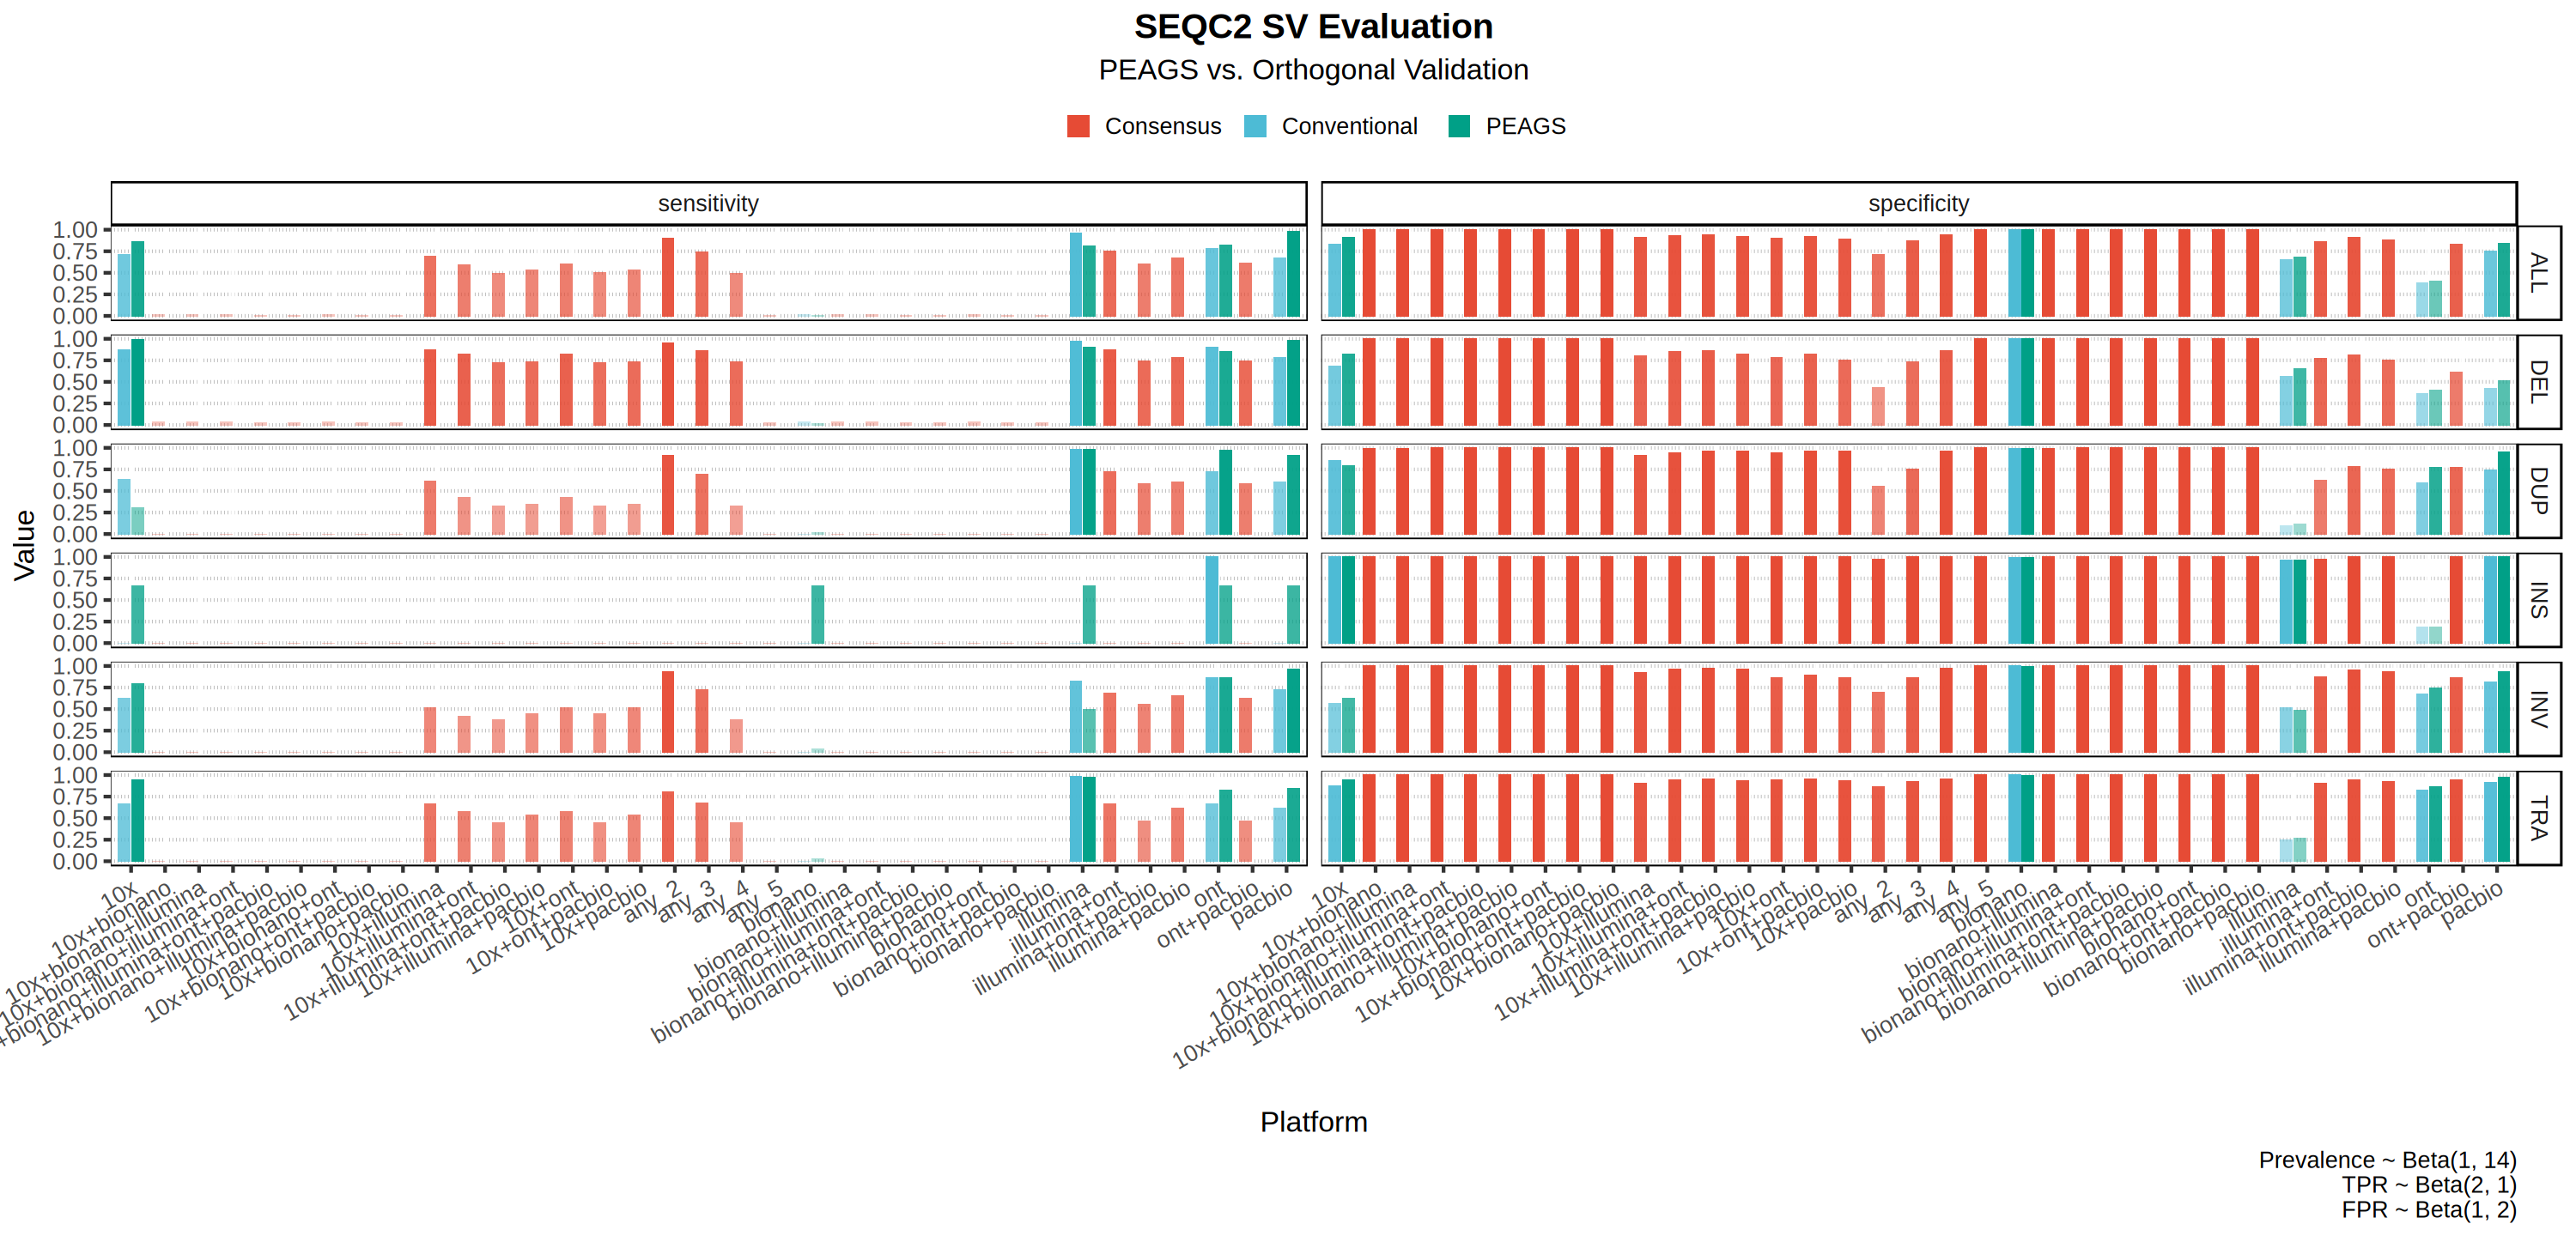

In [18]:
options(repr.plot.width = 25, repr.plot.height = 12)

res_long |>
ggplot(aes(x = platform, y = value, fill = method, alpha = value)) +
	facet_grid(svtype~metric) +
	geom_col(position = position_dodge(width = 0.8, preserve = "single"), width = 0.7) +
	labs(
		title = "SEQC2 SV Evaluation",
		subtitle = "PEAGS vs. Orthogonal Validation",
		caption = "Prevalence ~ Beta(1, 14)\nTPR ~ Beta(2, 1)\nFPR ~ Beta(1, 2)",
		x = "Platform",
		y = "Value",
		fill = NULL,
		alpha = NULL,
		linetype = NULL
	) +
	theme_pubclean(base_size = 20) +
	theme(
		plot.title = element_text(hjust = 0.5, face = "bold"),
		plot.subtitle = element_text(hjust = 0.5),
		plot.caption = element_text(hjust = 1),
		axis.text.x = element_text(angle = 30, hjust = 1),
		panel.border = element_rect(linewidth = 0.5),
		strip.background = element_rect(fill = "transparent", color = "black")
	) +
	scale_alpha(range = c(0.3, 1), guide = "none") +
	scale_fill_npg()

Warning message:
“Removed 35 rows containing missing values or values outside the scale range
(`geom_col()`).”


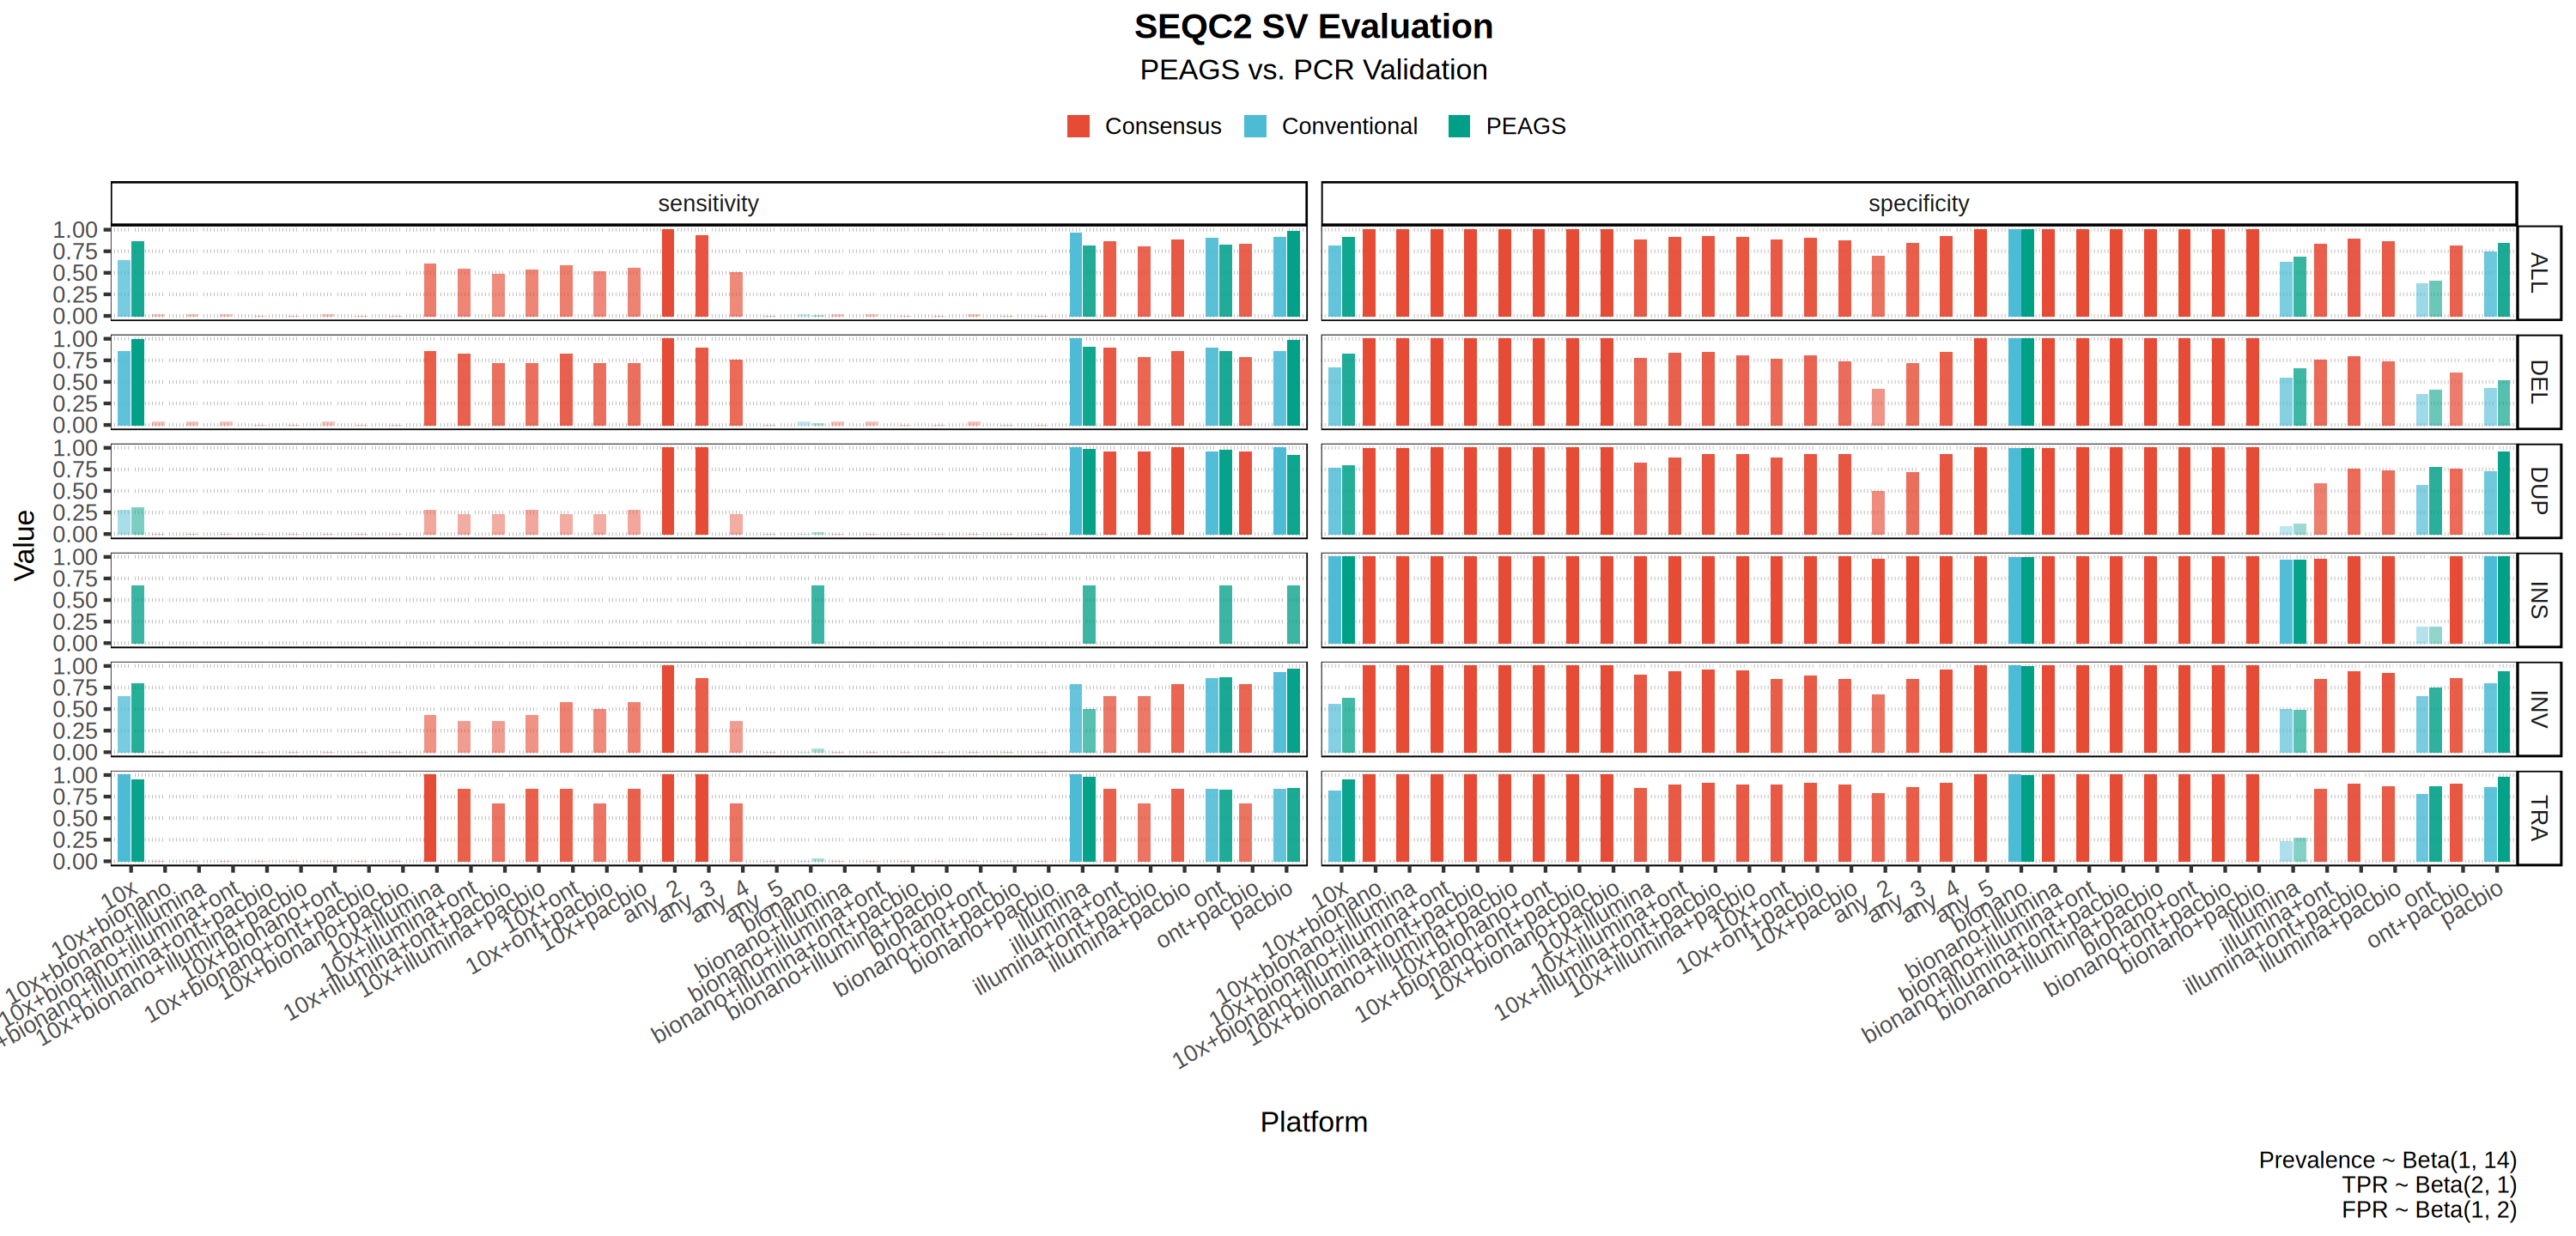

In [19]:
options(repr.plot.width = 25, repr.plot.height = 12)

res_pcr_long |>
ggplot(aes(x = platform, y = value, fill = method, alpha = value)) +
	facet_grid(svtype~metric) +
	geom_col(position = position_dodge(width = 0.8, preserve = "single"), width = 0.7) +
	labs(
		title = "SEQC2 SV Evaluation",
		subtitle = "PEAGS vs. PCR Validation",
		caption = "Prevalence ~ Beta(1, 14)\nTPR ~ Beta(2, 1)\nFPR ~ Beta(1, 2)",
		x = "Platform",
		y = "Value",
		fill = NULL,
		alpha = NULL,
		linetype = NULL
	) +
	theme_pubclean(base_size = 20) +
	theme(
		plot.title = element_text(hjust = 0.5, face = "bold"),
		plot.subtitle = element_text(hjust = 0.5),
		plot.caption = element_text(hjust = 1),
		axis.text.x = element_text(angle = 30, hjust = 1),
		panel.border = element_rect(linewidth = 0.5),
		strip.background = element_rect(fill = "transparent", color = "black")
	) +
	scale_alpha(range = c(0.3, 1), guide = "none") +
	scale_fill_npg()

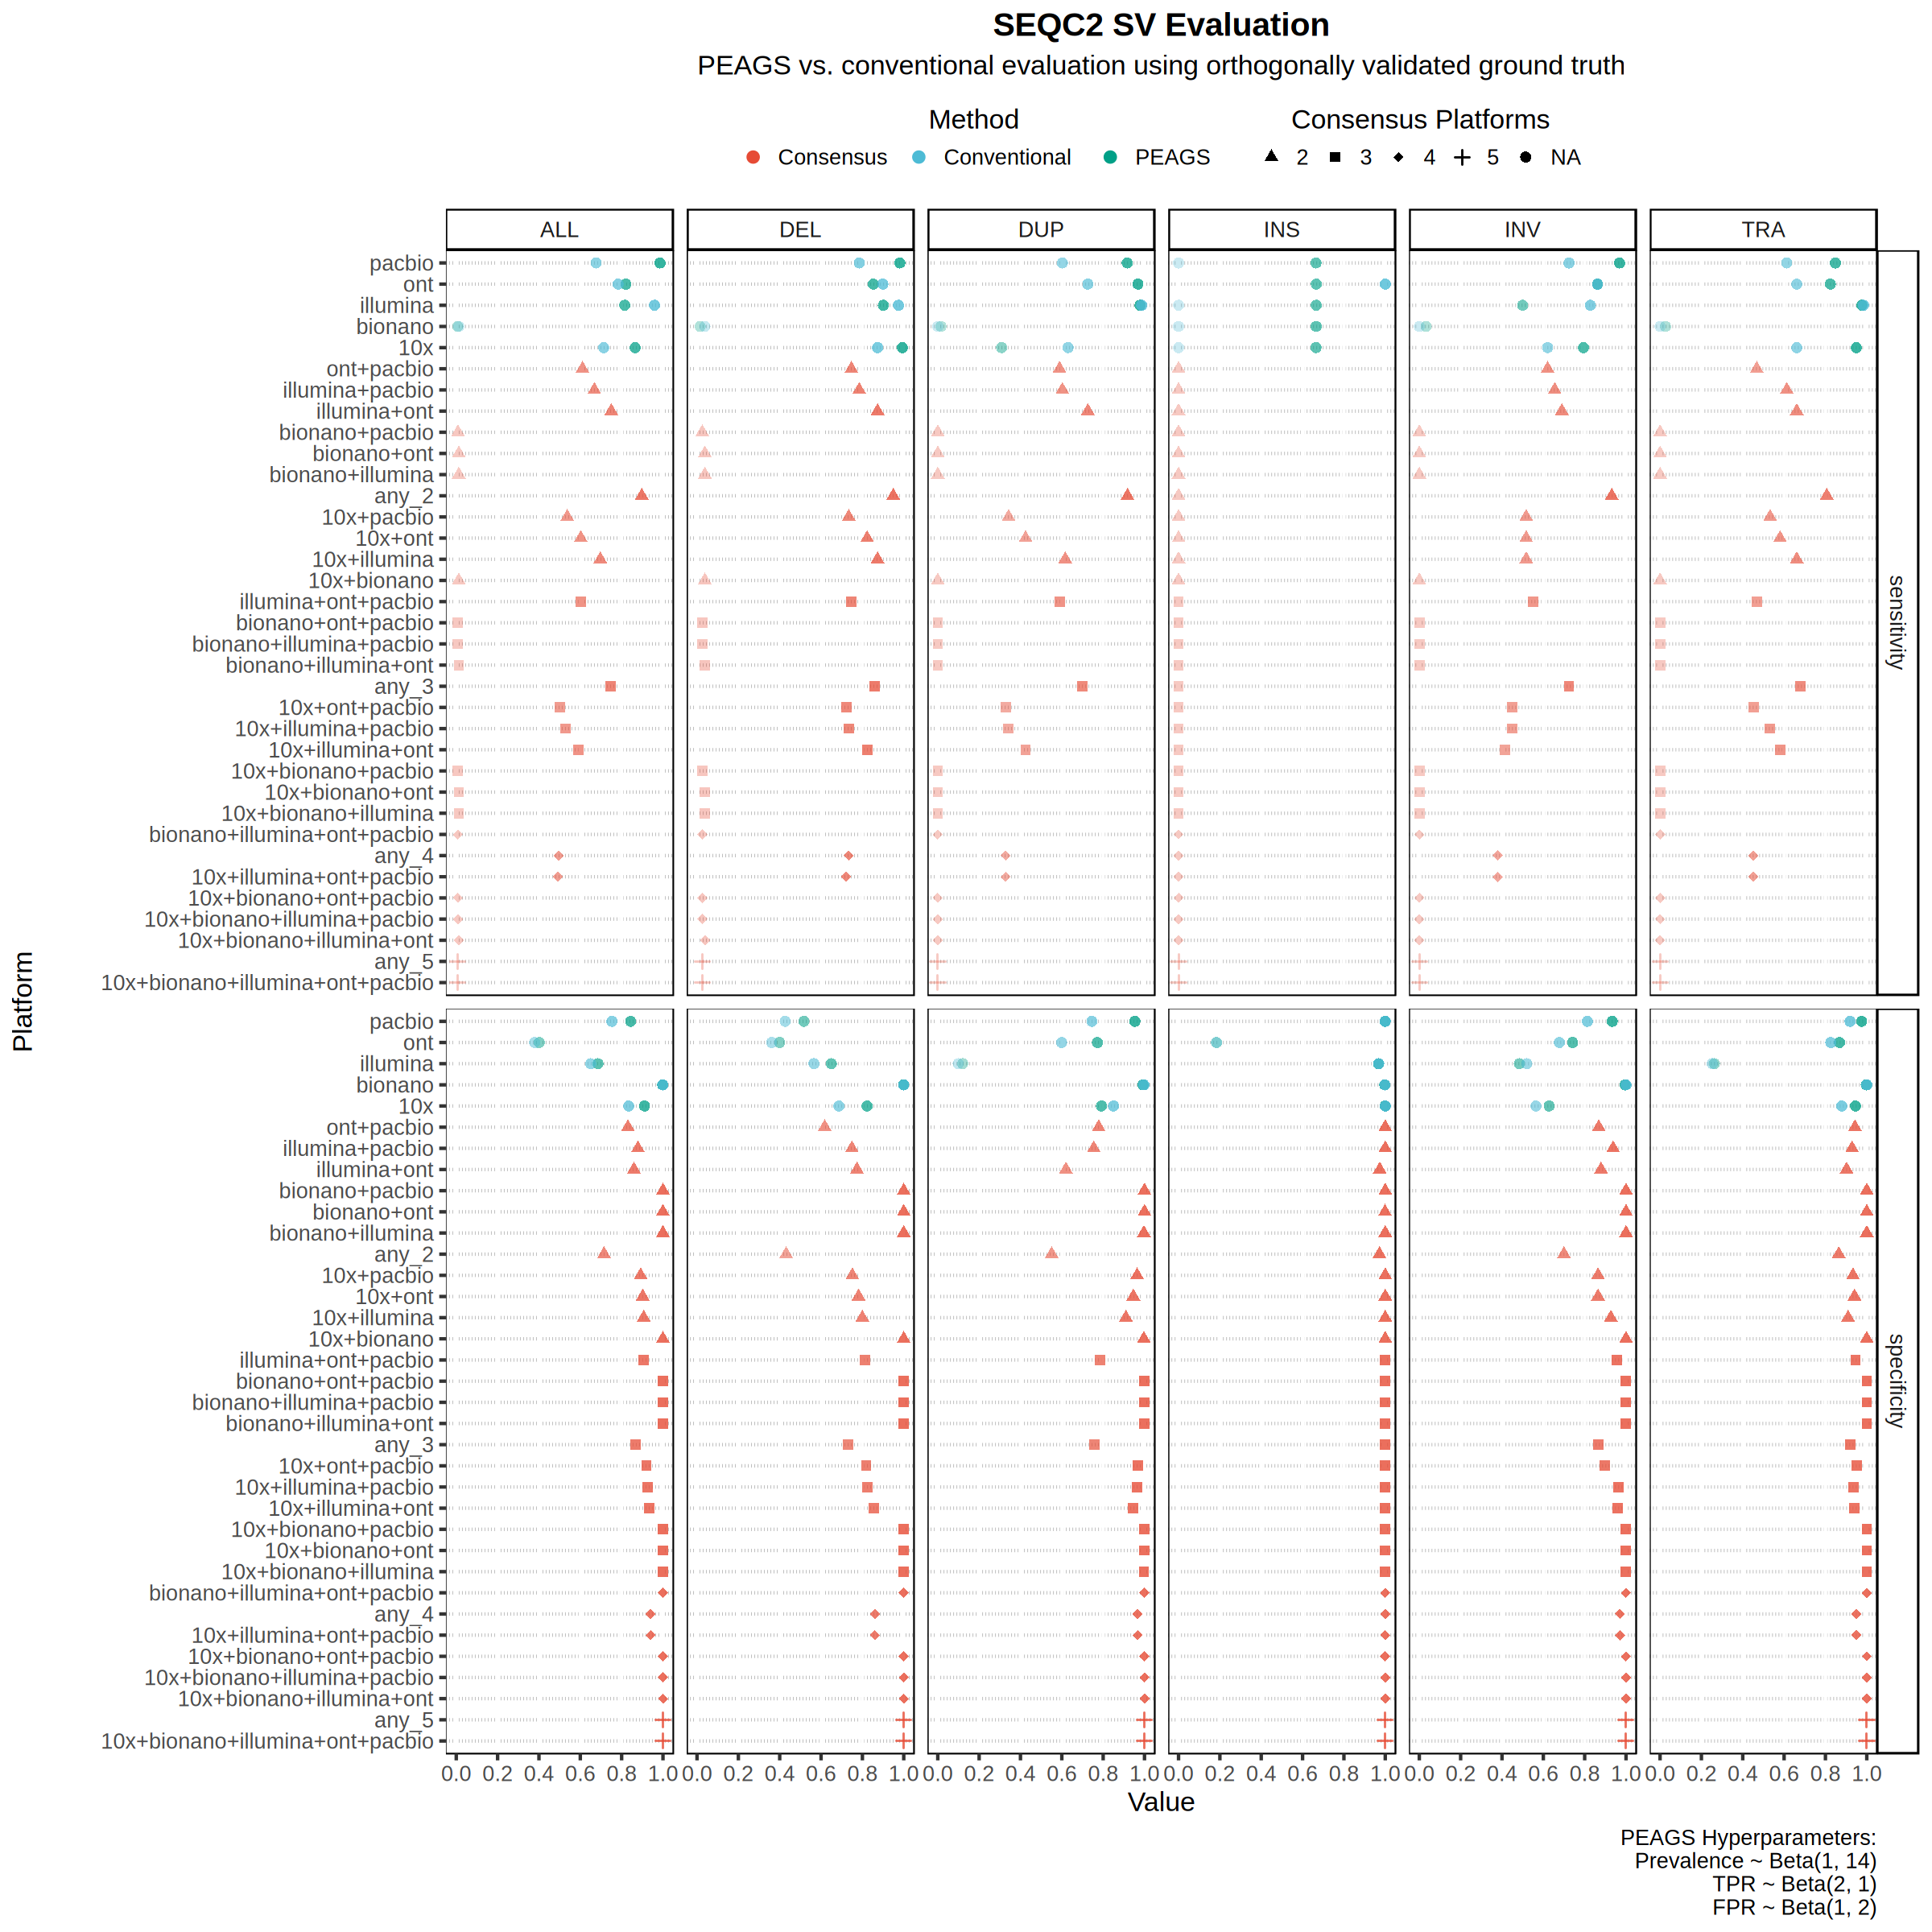

In [20]:
options(repr.plot.width = 20, repr.plot.height = 20)

res_long |>
	ggplot(aes(
		# Use -ifelse(...) to put NA at the TOP, or +ifelse(...) to put NA at the BOTTOM
		y     = reorder(platform, -ifelse(is.na(n_consensus), 0, n_consensus)),
		x     = value,
		color = method,
		alpha = value,
		shape = as.factor(n_consensus)
	)) +
	facet_grid(metric ~ svtype) +
	geom_point(size = 3) +
	labs(
		title    = "SEQC2 SV Evaluation",
		subtitle = "PEAGS vs. conventional evaluation using orthogonally validated ground truth",
		caption  = "PEAGS Hyperparameters:\nPrevalence ~ Beta(1, 14)\nTPR ~ Beta(2, 1)\nFPR ~ Beta(1, 2)",
		x        = "Value",
		y        = "Platform",
		fill     = NULL,
		color    = "Method",
		alpha    = NULL,
		linetype = NULL,
		shape    = "Consensus Platforms"
	) +
	theme_pubclean(base_size = 20) +
	theme(
		plot.title       = element_text(hjust = 0.5, face = "bold"),
		plot.subtitle    = element_text(hjust = 0.5),
		plot.caption     = element_text(hjust = 1),
		panel.border     = element_rect(linewidth = 0.5),
		strip.background = element_rect(fill = "transparent", color = "black"),
		# legend.box = "vertical",
		legend.title.position = "top",
		legend.title = element_text(hjust = 0.5)
	) +
	scale_alpha(range = c(0.3, 0.8), guide = "none") +
	scale_shape_manual(values = c(17, 15, 18, 3, 7, 8, 4, 9, 10), na.translate = TRUE, na.value = 16) +
	scale_x_continuous(breaks = seq(0, 1, by = 0.2), limits = c(0, 1)) +
	scale_color_npg()

Warning message:
“Removed 35 rows containing missing values or values outside the scale range
(`geom_point()`).”


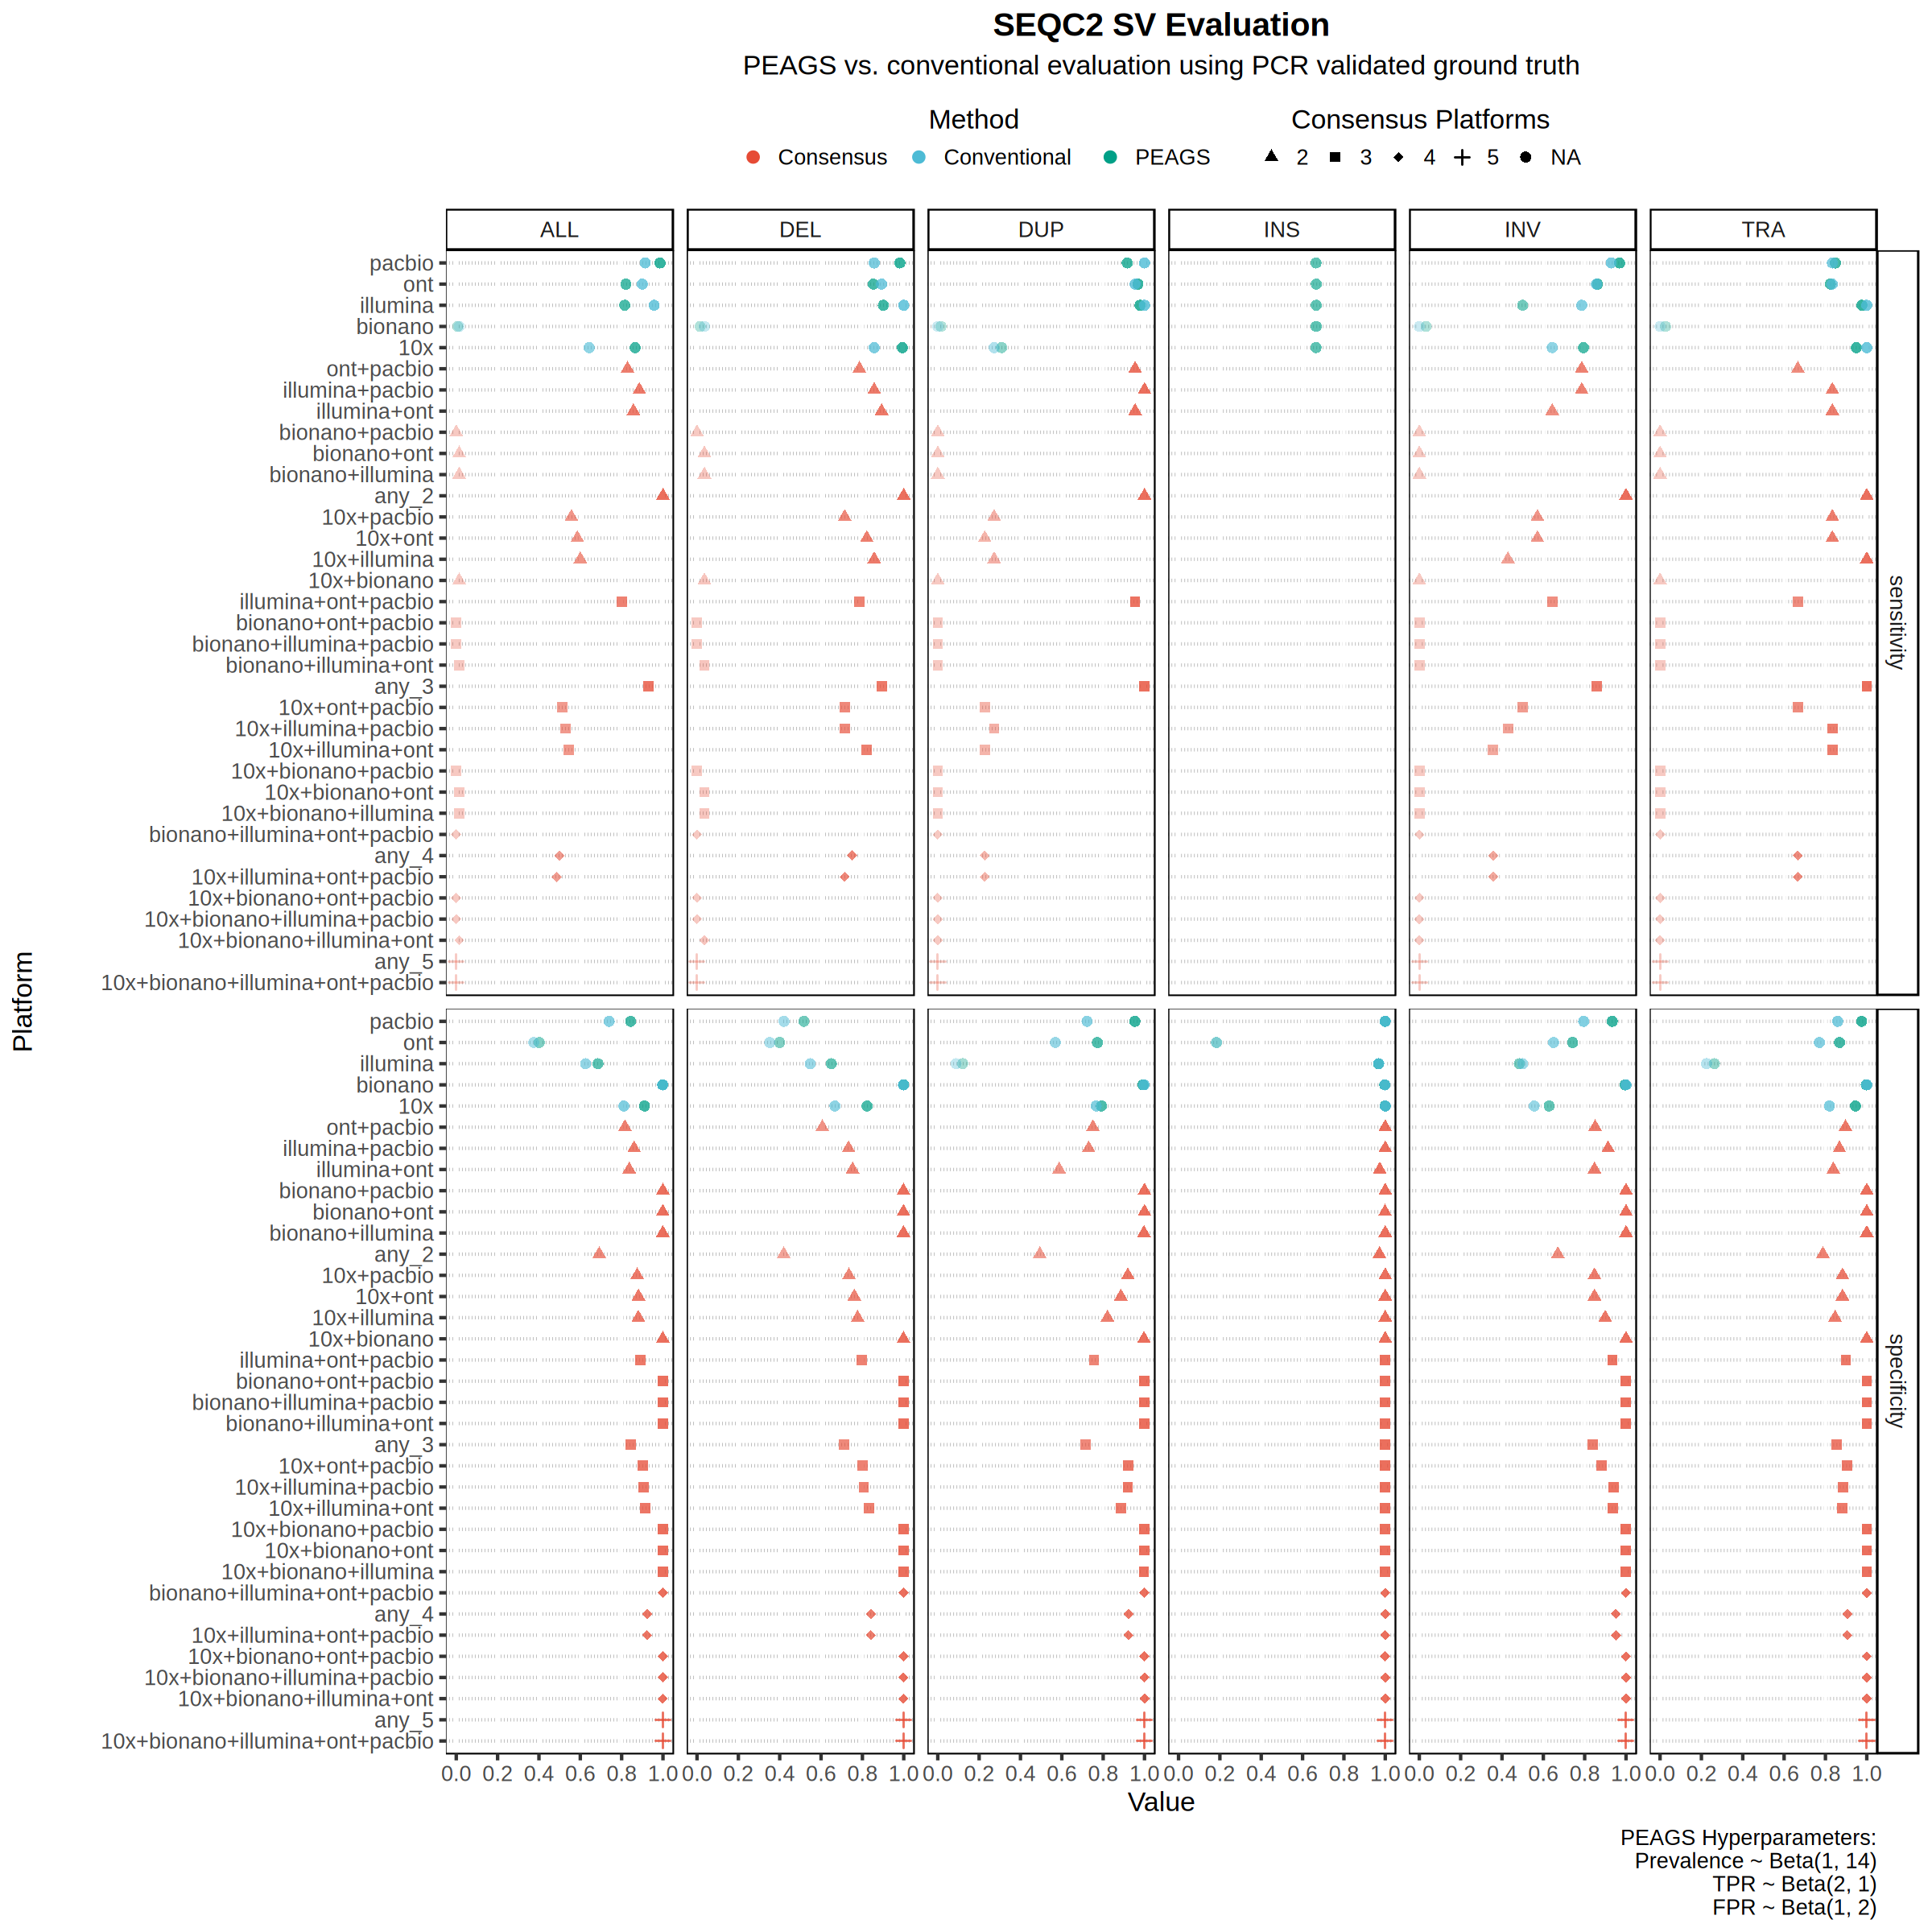

In [21]:
options(repr.plot.width = 20, repr.plot.height = 20)

res_pcr_long |>
	ggplot(aes(
		# Use -ifelse(...) to put NA at the TOP, or +ifelse(...) to put NA at the BOTTOM
		y     = reorder(platform, -ifelse(is.na(n_consensus), 0, n_consensus)),
		x     = value,
		color = method,
		alpha = value,
		shape = as.factor(n_consensus)
	)) +
	facet_grid(metric ~ svtype) +
	geom_point(size = 3) +
	labs(
		title    = "SEQC2 SV Evaluation",
		subtitle = "PEAGS vs. conventional evaluation using PCR validated ground truth",
		caption  = "PEAGS Hyperparameters:\nPrevalence ~ Beta(1, 14)\nTPR ~ Beta(2, 1)\nFPR ~ Beta(1, 2)",
		x        = "Value",
		y        = "Platform",
		fill     = NULL,
		color    = "Method",
		alpha    = NULL,
		linetype = NULL,
		shape    = "Consensus Platforms"
	) +
	theme_pubclean(base_size = 20) +
	theme(
		plot.title       = element_text(hjust = 0.5, face = "bold"),
		plot.subtitle    = element_text(hjust = 0.5),
		plot.caption     = element_text(hjust = 1),
		panel.border     = element_rect(linewidth = 0.5),
		strip.background = element_rect(fill = "transparent", color = "black"),
		# legend.box = "vertical",
		legend.title.position = "top",
		legend.title = element_text(hjust = 0.5)
	) +
	scale_alpha(range = c(0.3, 0.8), guide = "none") +
	scale_shape_manual(values = c(17, 15, 18, 3, 7, 8, 4, 9, 10), na.translate = TRUE, na.value = 16) +
	scale_x_continuous(breaks = seq(0, 1, by = 0.2), limits = c(0, 1)) +
	scale_color_npg()

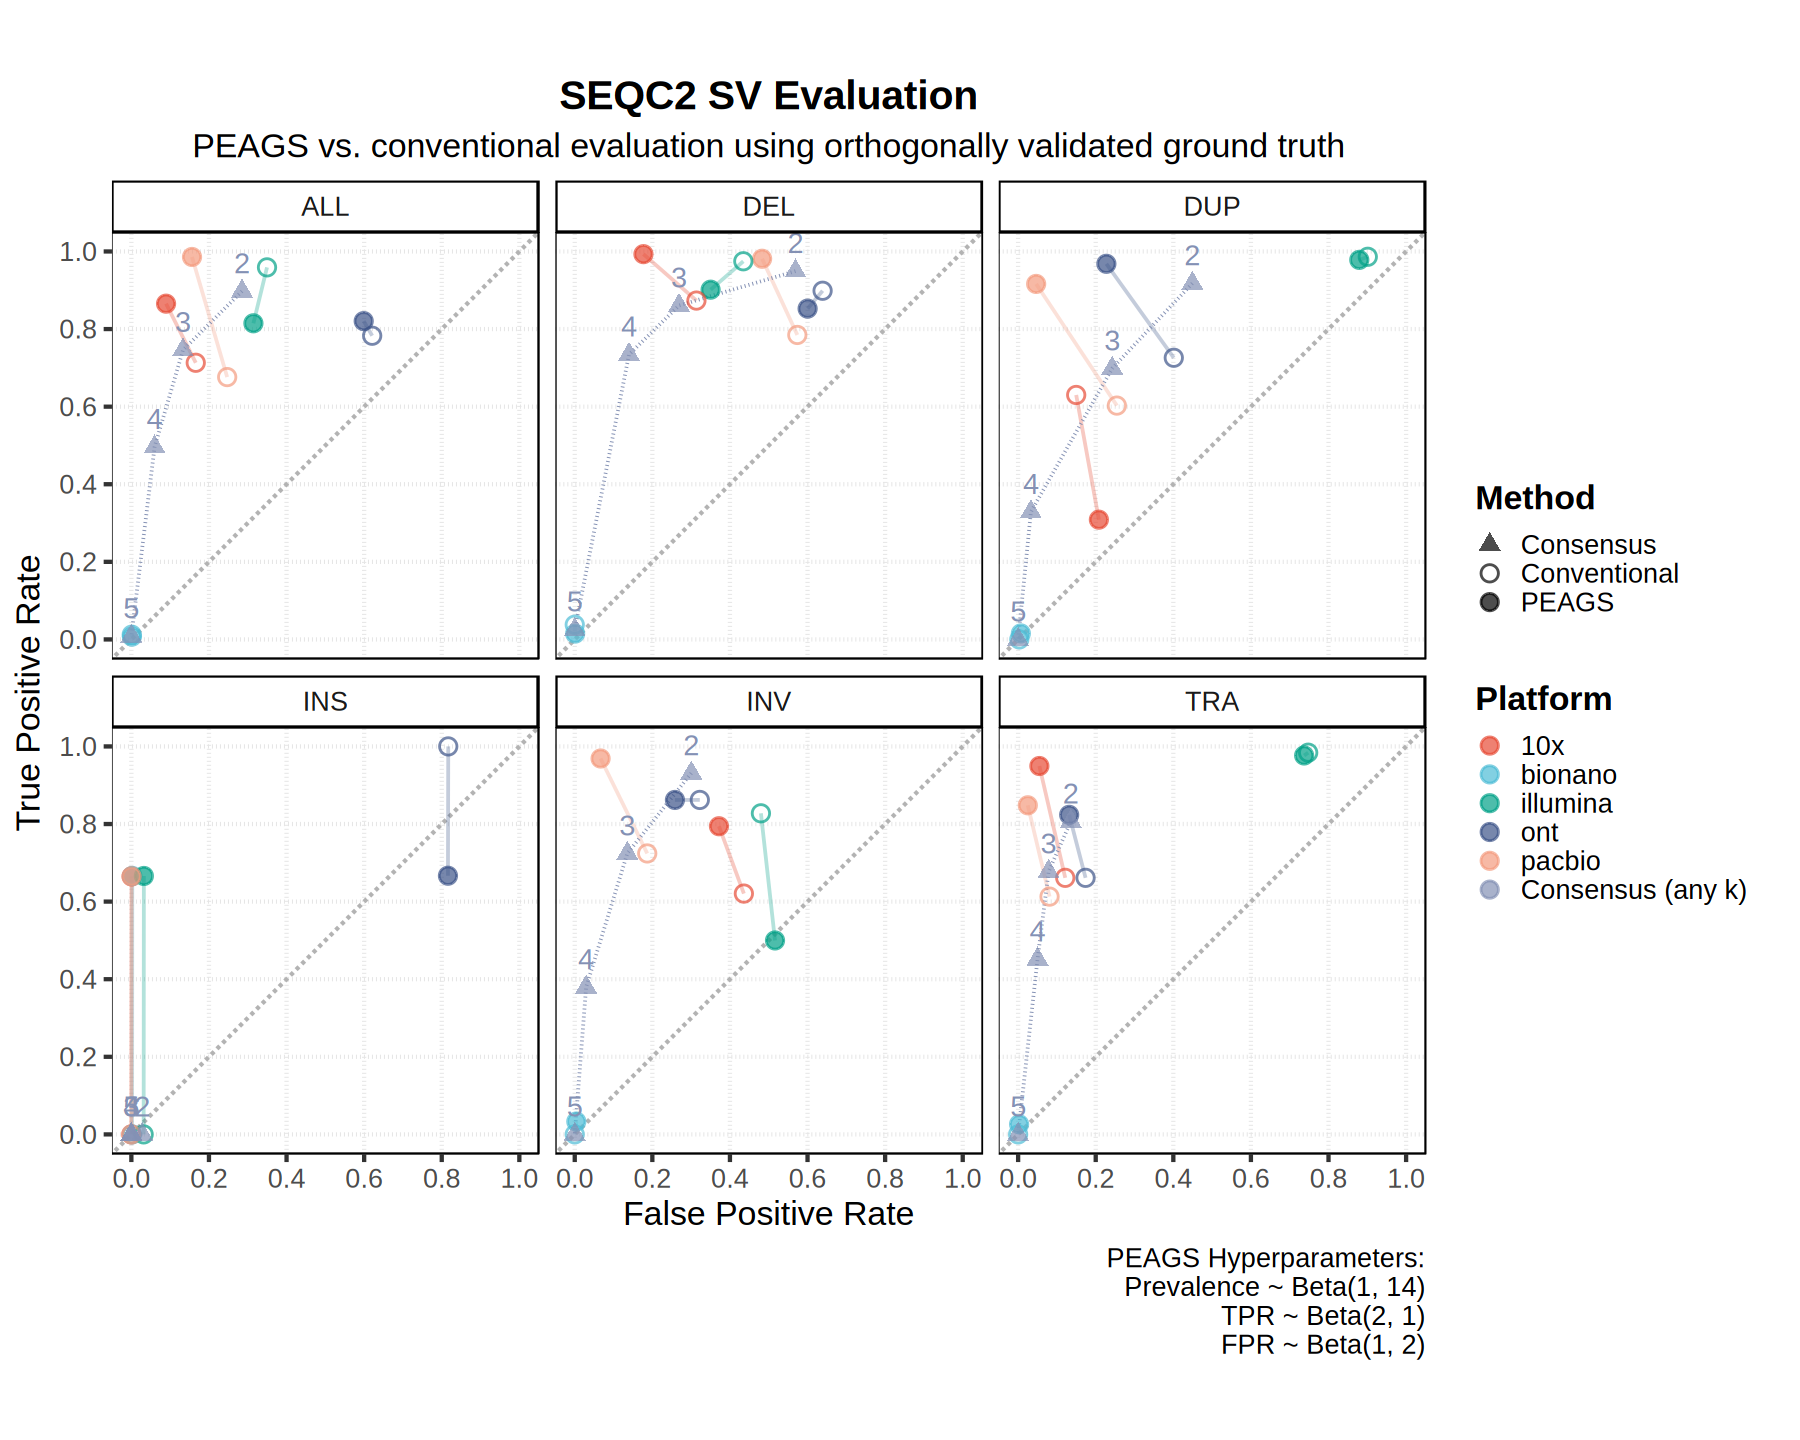

In [22]:
	options(repr.plot.width = 15, repr.plot.height = 12)

	res |>
	# Keep only individual platforms (n_consensus is NA) and "any_k" consensus rules
	subset(is.na(n_consensus) | grepl("^any_", platform)) |>
	mutate(
		platform_color = ifelse(method == "Consensus", "Consensus (any k)", platform),
		# Order legend so individual platforms appear first and "Consensus (any k)" is last
		platform_color = reorder(platform_color, ifelse(method == "Consensus", 1, 0))
	) |>
	ggplot(aes(
		x     = 1 - specificity,
		y     = sensitivity,
		color = platform_color,
		shape = method
	)) +
	facet_wrap(~ svtype, nrow = 2) +
	# Diagonal chance line
	geom_abline(slope = 1, intercept = 0, linetype = "dashed", color = "grey70") +
	# Connect PEAGS and Conventional for the exact same platform with a colored line
	geom_line(
		data = ~ subset(.x, method != "Consensus"),
		aes(group = platform),
		linewidth = 0.8,
		alpha = 0.3,
		show.legend = FALSE
	) +
	# Connect the "any_k" consensus trajectory (ordered by k)
	geom_path(
		data = ~ subset(.x, method == "Consensus")[order(subset(.x, method == "Consensus")$n_consensus), ],
		aes(group = method),
		linetype = "dotted",
		linewidth = 0.8,
		show.legend = FALSE
	) +
	geom_point(size = 4, alpha = 0.7) +
	# Annotate the consensus threshold k (2, 3, 4...) directly in the plot
	geom_text(
		data = ~ subset(.x, method == "Consensus"),
		aes(label = n_consensus),
		vjust = -0.9,
		hjust = 0.5,
		size = 6,
		fontface = "plain",
		show.legend = FALSE
	) +
	coord_equal(xlim = c(0, 1), ylim = c(0, 1)) +
	labs(
		title    = "SEQC2 SV Evaluation",
		subtitle = "PEAGS vs. conventional evaluation using orthogonally validated ground truth",
		caption  = "PEAGS Hyperparameters:\nPrevalence ~ Beta(1, 14)\nTPR ~ Beta(2, 1)\nFPR ~ Beta(1, 2)",
		x        = "False Positive Rate",
		y        = "True Positive Rate",
		color    = "Platform",
		shape    = "Method"
	) +
	theme_pubclean(base_size = 20) +
	theme(
		plot.title       = element_text(hjust = 0.5, face = "bold"),
		plot.subtitle    = element_text(hjust = 0.5),
		plot.caption     = element_text(hjust = 1),
		panel.border     = element_rect(linewidth = 0.5, fill = NA),
		panel.grid.major.y = element_line(color = "grey90", linetype = "dotted"),
		panel.grid.major.x = element_line(color = "grey90", linetype = "dotted"),
		strip.background = element_rect(fill = "transparent", color = "black"),
		legend.position  = "right",
		legend.box       = "vertical",
		legend.title     = element_text(face = "bold")
	) +
	scale_shape_manual(values = c("PEAGS" = 19, "Conventional" = 21, "Consensus" = 17)) +
	scale_x_continuous(breaks = seq(0, 1, by = 0.2)) +
	scale_y_continuous(breaks = seq(0, 1, by = 0.2)) +
	scale_color_npg()

Warning message:
“Removed 5 rows containing missing values or values outside the scale range
(`geom_line()`).”
`geom_line()`: Each group consists of only one observation.
ℹ Do you need to adjust the group aesthetic?
Warning message:
“Removed 4 rows containing missing values or values outside the scale range
(`geom_path()`).”
Warning message:
“Removed 9 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 4 rows containing missing values or values outside the scale range
(`geom_text()`).”


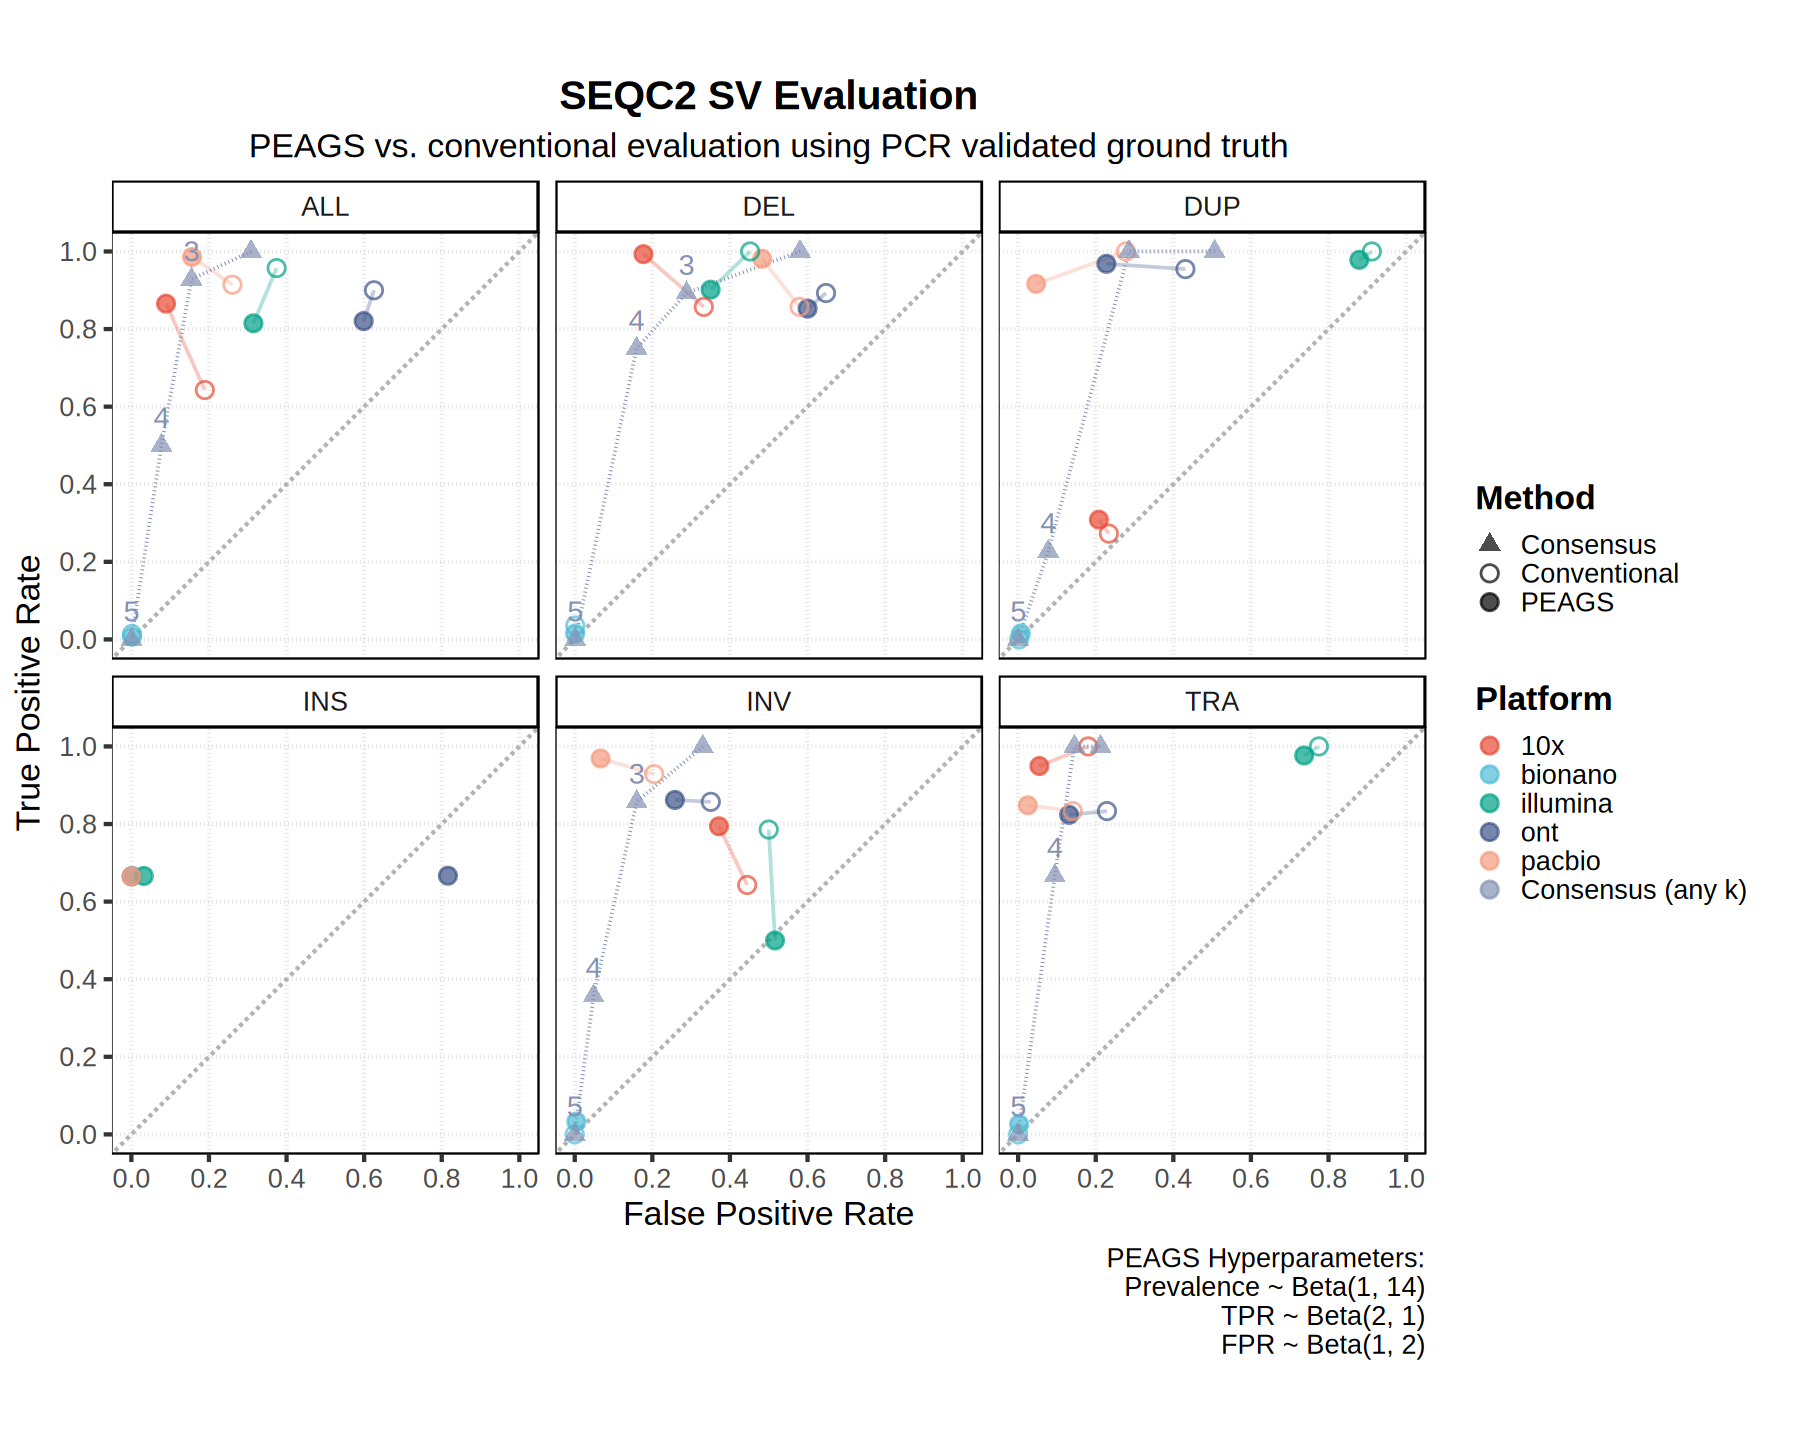

In [23]:
	options(repr.plot.width = 15, repr.plot.height = 12)

	res_pcr |>
	# Keep only individual platforms (n_consensus is NA) and "any_k" consensus rules
	subset(is.na(n_consensus) | grepl("^any_", platform)) |>
	mutate(
		platform_color = ifelse(method == "Consensus", "Consensus (any k)", platform),
		# Order legend so individual platforms appear first and "Consensus (any k)" is last
		platform_color = reorder(platform_color, ifelse(method == "Consensus", 1, 0))
	) |>
	ggplot(aes(
		x     = 1 - specificity,
		y     = sensitivity,
		color = platform_color,
		shape = method
	)) +
	facet_wrap(~ svtype, nrow = 2) +
	# Diagonal chance line
	geom_abline(slope = 1, intercept = 0, linetype = "dashed", color = "grey70") +
	# Connect PEAGS and Conventional for the exact same platform with a colored line
	geom_line(
		data = ~ subset(.x, method != "Consensus"),
		aes(group = platform),
		linewidth = 0.8,
		alpha = 0.3,
		show.legend = FALSE
	) +
	# Connect the "any_k" consensus trajectory (ordered by k)
	geom_path(
		data = ~ subset(.x, method == "Consensus")[order(subset(.x, method == "Consensus")$n_consensus), ],
		aes(group = method),
		linetype = "dotted",
		linewidth = 0.8,
		show.legend = FALSE
	) +
	geom_point(size = 4, alpha = 0.7) +
	# Annotate the consensus threshold k (2, 3, 4...) directly in the plot
	geom_text(
		data = ~ subset(.x, method == "Consensus"),
		aes(label = n_consensus),
		vjust = -0.9,
		hjust = 0.5,
		size = 6,
		fontface = "plain",
		show.legend = FALSE
	) +
	coord_equal(xlim = c(0, 1), ylim = c(0, 1)) +
	labs(
		title    = "SEQC2 SV Evaluation",
		subtitle = "PEAGS vs. conventional evaluation using PCR validated ground truth",
		caption  = "PEAGS Hyperparameters:\nPrevalence ~ Beta(1, 14)\nTPR ~ Beta(2, 1)\nFPR ~ Beta(1, 2)",
		x        = "False Positive Rate",
		y        = "True Positive Rate",
		color    = "Platform",
		shape    = "Method"
	) +
	theme_pubclean(base_size = 20) +
	theme(
		plot.title       = element_text(hjust = 0.5, face = "bold"),
		plot.subtitle    = element_text(hjust = 0.5),
		plot.caption     = element_text(hjust = 1),
		panel.border     = element_rect(linewidth = 0.5, fill = NA),
		panel.grid.major.y = element_line(color = "grey90", linetype = "dotted"),
		panel.grid.major.x = element_line(color = "grey90", linetype = "dotted"),
		strip.background = element_rect(fill = "transparent", color = "black"),
		legend.position  = "right",
		legend.box       = "vertical",
		legend.title     = element_text(face = "bold")
	) +
	scale_shape_manual(values = c("PEAGS" = 19, "Conventional" = 21, "Consensus" = 17)) +
	scale_x_continuous(breaks = seq(0, 1, by = 0.2)) +
	scale_y_continuous(breaks = seq(0, 1, by = 0.2)) +
	scale_color_npg()

## Correlation

In [ ]:
# intersection-based evaluation (leave-one-out version)
df_mat  <- read_parquet(path)
sv_cols <- unique(subset(all_method_result_pcr, method == "PEAGS")$platform)
subsets <- c(list(ALL = df_mat), split(df_mat, df_mat$svtype))

## LOO
intersect_perf <- bind_rows(lapply(names(subsets), function(s) {
  X <- as.matrix(subsets[[s]][, sv_cols]) > 0
  n <- rowSums(X)
  bind_rows(lapply(2:(length(sv_cols) - 1), function(k)
    bind_rows(lapply(seq_along(sv_cols), function(j)
      data.frame(svtype = s, method = paste0("Intersection LOO ", k, "+"),
                 platform = sv_cols[j],
                 compute_binary_metrics(X[, j, drop = FALSE], (n - X[, j]) >= k))))))
}))

# ## Non-LOO
# intersect_perf <- bind_rows(lapply(names(subsets), function(s) {
#   X <- as.matrix(subsets[[s]][, sv_cols]) > 0
#   n <- rowSums(X)
#   bind_rows(lapply(2:length(sv_cols), function(k)
#     data.frame(svtype = s, method = paste0("Intersection ", k, "+"), platform = sv_cols,
#                compute_binary_metrics(X, n >= k))))
# }))

In [25]:
# %% Cell 2: pair each estimate with the PCR-truth value
to_long <- function(d, val) {
  d |> select(any_of(c("method", "svtype", "platform")), sensitivity, specificity) |>
    pivot_longer(c(sensitivity, specificity), names_to = "metric", values_to = val)
}

pcr_truth <- all_method_result_pcr |> 
	filter(method == "Conventional") |>
	to_long("truth") |> 
	select(-method)

pcr_peags <- bind_rows(filter(all_method_result_pcr, method == "PEAGS"), intersect_perf) |>
  to_long("estimate")

pcr_paired <- inner_join(pcr_peags, pcr_truth, by = c("svtype", "platform", "metric"))

In [26]:
orthogonal_truth <- all_method_result |> 
	filter(method == "Conventional") |>
	to_long("truth") |> 
	select(-method)

orthogonal_peags <- bind_rows(filter(all_method_result, method == "PEAGS"), intersect_perf) |>
  to_long("estimate")

orthogonal_paired <- inner_join(orthogonal_peags, orthogonal_truth, by = c("svtype", "platform", "metric"))

In [ ]:
# correlation scores
pcr_cor_tbl <- pcr_paired |>
  group_by(method, metric) |>
  summarise(
    n        = sum(complete.cases(estimate, truth)),
    pearson  = cor(estimate, truth, use = "complete.obs"),
    spearman = cor(estimate, truth, use = "complete.obs", method = "spearman"),
    mae      = mean(abs(estimate - truth), na.rm = TRUE),
    .groups  = "drop"
  )
pcr_cor_tbl
qwrite(pcr_cor_tbl, "seqc2_correlation_pcr-truth.tsv")

method,metric,n,pearson,spearman,mae
<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
Intersection LOO 2+,sensitivity,25,0.9282214,0.7447865,0.171618699
Intersection LOO 2+,specificity,30,0.9722479,0.9824521,0.057667211
Intersection LOO 3+,sensitivity,25,0.9667699,0.8183667,0.067266829
Intersection LOO 3+,specificity,30,0.9918869,0.9948667,0.029280152
Intersection LOO 4+,sensitivity,13,0.9506906,0.8209908,0.094232784
Intersection LOO 4+,specificity,30,0.9993049,0.9977703,0.008023644
PEAGS,sensitivity,25,0.9636338,0.7412117,0.070108718
PEAGS,specificity,30,0.9696717,0.9773922,0.063217527


In [ ]:
# correlation scores
orthogonal_cor_tbl <- orthogonal_paired |>
  group_by(method, metric) |>
  summarise(
    n        = sum(complete.cases(estimate, truth)),
    pearson  = cor(estimate, truth, use = "complete.obs"),
    spearman = cor(estimate, truth, use = "complete.obs", method = "spearman"),
    mae      = mean(abs(estimate - truth), na.rm = TRUE),
    .groups  = "drop"
  )
orthogonal_cor_tbl
qwrite(orthogonal_cor_tbl, "seqc2_correlation_orthogonal-truth.tsv")

method,metric,n,pearson,spearman,mae
<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
Intersection LOO 2+,sensitivity,29,0.9163270,0.7586920,0.10835031
Intersection LOO 2+,specificity,30,0.9777075,0.9768341,0.04468184
Intersection LOO 3+,sensitivity,25,0.9028268,0.7053382,0.11077811
Intersection LOO 3+,specificity,30,0.9937069,0.9932961,0.01976040
Intersection LOO 4+,sensitivity,13,0.9775751,0.9018347,0.07408873
Intersection LOO 4+,specificity,30,0.9953542,0.9970988,0.02612858
PEAGS,sensitivity,30,0.7162955,0.6207019,0.21671633
PEAGS,specificity,30,0.9749513,0.9733548,0.05039301


Warning message:
“Removed 32 rows containing missing values or values outside the scale range
(`geom_point()`).”


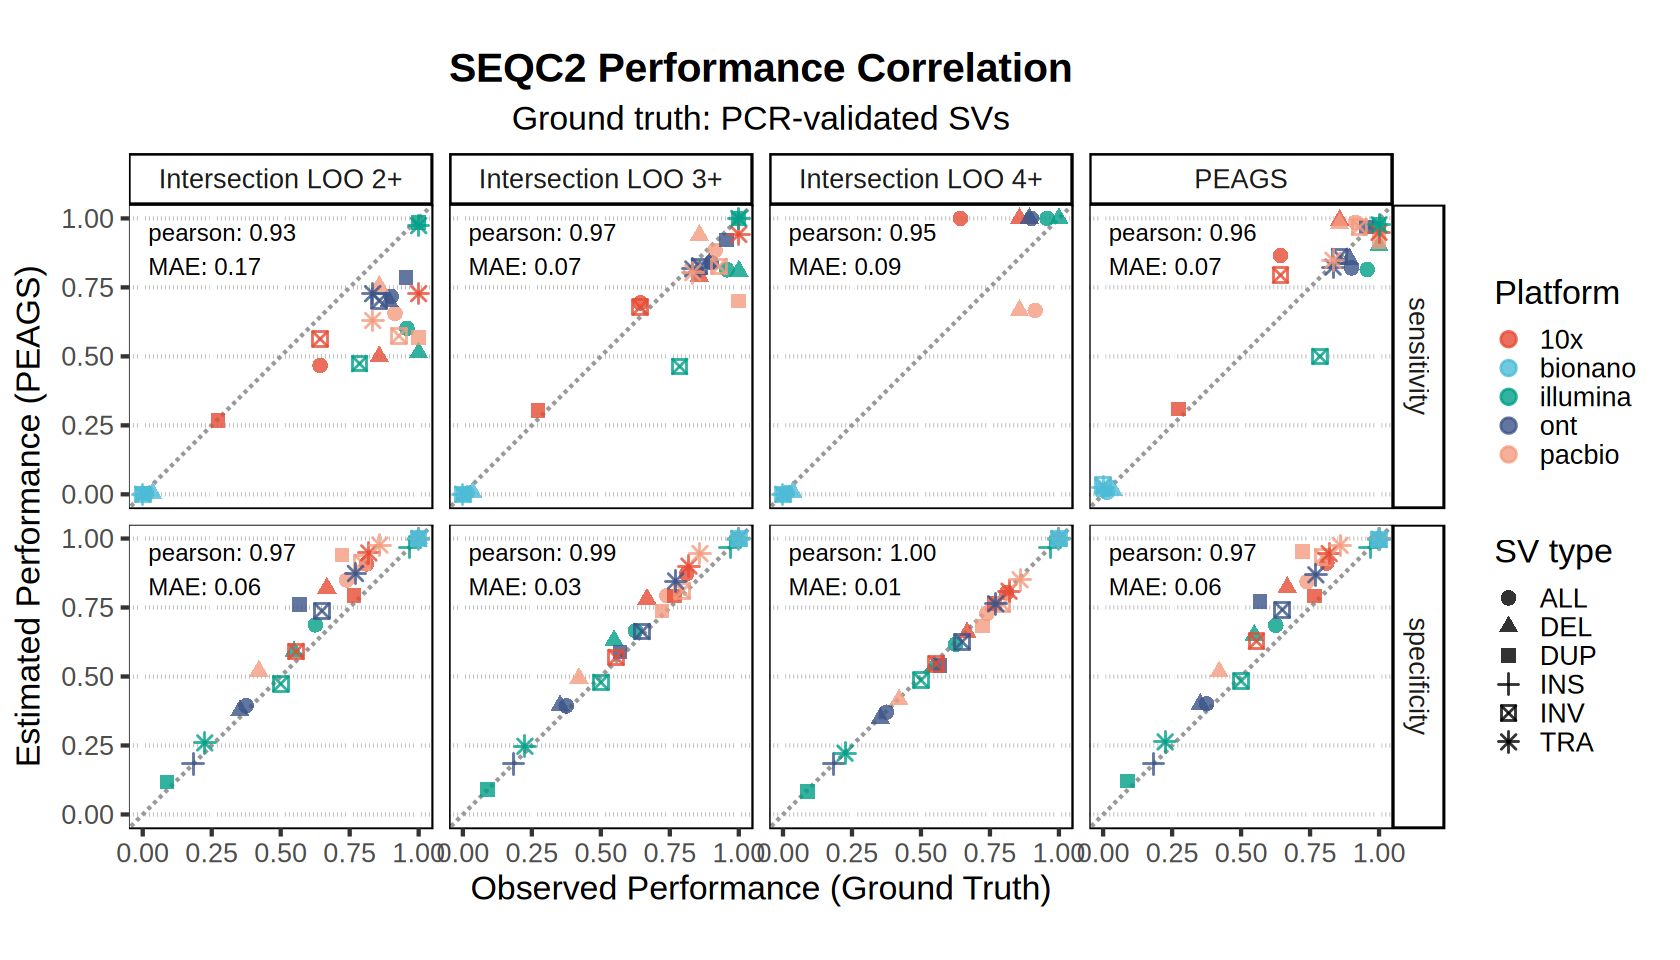

In [ ]:
# one plot
options(repr.plot.width = 14, repr.plot.height = 8)

pcr_lab <- pcr_cor_tbl |> mutate(label = sprintf("pearson: %.2f\nMAE: %.2f", pearson, mae))

ggplot(pcr_paired, aes(truth, estimate)) +
	geom_abline(linetype = "dashed", color = "grey60") +
	geom_point(aes(color = platform, shape = svtype), size = 3.5, alpha = 0.8) +
	geom_text(data = pcr_lab, aes(x = 0.02, y = 0.98, label = label), hjust = 0, vjust = 1, size = 5) +
	facet_grid(metric ~ method) +
	coord_equal(xlim = c(0, 1), ylim = c(0, 1)) +
	labs(
		title = "SEQC2 Performance Correlation",
		subtitle = "Ground truth: PCR-validated SVs",
		x = "Observed Performance (Ground Truth)", y = "Estimated Performance (PEAGS)",
		color = "Platform",
		shape = "SV type"
	) +
	theme_pubclean(base_size = 20) +
	theme(
		plot.title = element_text(hjust = 0.5, face = "bold"),
		plot.subtitle = element_text(hjust = 0.5),
		panel.border = element_rect(linewidth = 0.5, fill = NA),
		strip.background = element_rect(fill = "transparent", color = "black"),
		legend.position = "right"
	) +
	scale_color_npg()

Warning message:
“Removed 23 rows containing missing values or values outside the scale range
(`geom_point()`).”


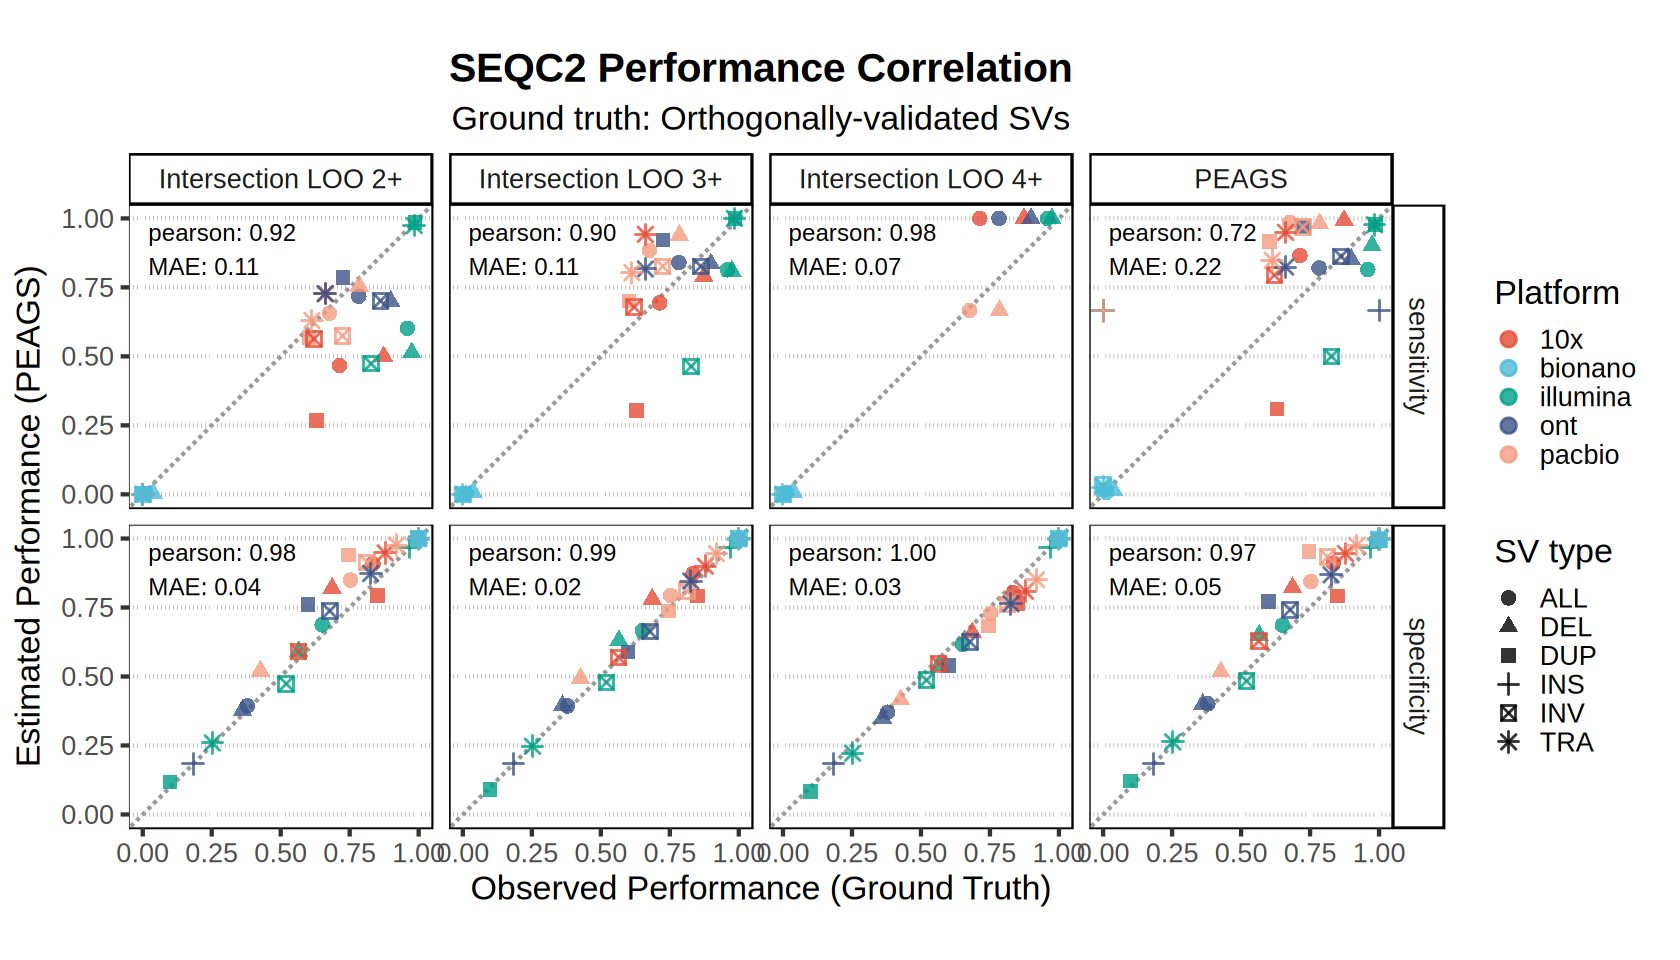

In [30]:
# %% Cell 4: one plot
options(repr.plot.width = 14, repr.plot.height = 8)

orthogonal_lab <- orthogonal_cor_tbl |> mutate(label = sprintf("pearson: %.2f\nMAE: %.2f", pearson, mae))

ggplot(orthogonal_paired, aes(truth, estimate)) +
	geom_abline(linetype = "dashed", color = "grey60") +
	geom_point(aes(color = platform, shape = svtype), size = 3.5, alpha = 0.8) +
	geom_text(data = orthogonal_lab, aes(x = 0.02, y = 0.98, label = label), hjust = 0, vjust = 1, size = 5) +
	facet_grid(metric ~ method) +
	coord_equal(xlim = c(0, 1), ylim = c(0, 1)) +
	labs(
		title = "SEQC2 Performance Correlation",
		subtitle = "Ground truth: Orthogonally-validated SVs",
		x = "Observed Performance (Ground Truth)", y = "Estimated Performance (PEAGS)",
		color = "Platform",
		shape = "SV type"
	) +
	theme_pubclean(base_size = 20) +
	theme(
		plot.title = element_text(hjust = 0.5, face = "bold"),
		plot.subtitle = element_text(hjust = 0.5),
		panel.border = element_rect(linewidth = 0.5, fill = NA),
		strip.background = element_rect(fill = "transparent", color = "black"),
		legend.position = "right"
	) +
	scale_color_npg()